# 04. Multi-Scale Benchmark Summary, Cross-Engine Scaling & Executive TCO Analysis

This notebook aggregates JSONL telemetry emitted by Notebooks `01`, `02`, and `03` across all executed scale presets (**`small_1g` -> `medium_100g` -> `large_500g`**) and evaluates **Compute Correctness, Multi-Scale Performance Curves, Slot-to-vCPU Equivalency, Python UDF Fallback Normalized Impact, and Hardware-Accurate Cloud TCO**.

### Architecture Variants Compared
| Engine Variant | Execution Runtime | Storage Format | Key Architectural Trait |
| :--- | :--- | :--- | :--- |
| **`spark_standard`** | Dataproc GCE Standard Spark | GCS Parquet | Open-source Spark 3.5 baseline |
| **`spark_lightning_base`** | Dataproc Lightning Engine (Base) | GCS Parquet | Proprietary optimizations + fast GCS connector (`+$0.0025/vCPU-hr` surcharge) |
| **`spark_lightning_nqe`** | Dataproc Lightning Engine + NQE | GCS Parquet | Native C++ Gluten/Velox vectorized execution (falls back to JVM/Python on scalar `@F.udf`) |
| **`bigframes_biglake_gcs`** | BigQuery DataFrames (`bigframes`) | BigLake External GCS Parquet (Stage 1) -> Native BQ Silver (Stages 2A/2B/3) | Serverless BigQuery SQL transpilation over shared Bronze GCS Parquet |
| **`bigframes_native_bq`** | BigQuery DataFrames (`bigframes`) | Native BQ Capacitor Storage | Serverless BigQuery SQL transpilation with native Capacitor column pruning |

### Important Benchmark Methodology & Cost Modeling Notes
1. **Timer Boundaries:** Spark stages measure warm in-cluster execution (`df.write...` excluding `SparkSession` startup); BigFrames measures end-to-end client orchestration + BigQuery execution (`bq_total_slot_ms` captures exact server compute without client HTTP polling). At `small_1g` (~1 GB), client API round-trip overhead is prominent on BigFrames and **amortizes sharply** at `medium_100g` (~100 GB) and `large_500g` (~500 GB).
2. **Hardware Topology & NVMe Local SSD Scaling:** `small_1g` runs Spark on `16` worker vCPUs (`2 x n2d-standard-8`, `1` NVMe Local SSD/worker = **`2` SSDs total**) vs. `100` BigQuery Enterprise slots; `medium_100g` and `large_500g` scale Spark to `64` worker vCPUs (`4 x n2d-standard-16`, `2` NVMe Local SSDs/worker = **`8` SSDs total**) vs. `200` BigQuery Enterprise slots. TCO calculations automatically bill exact per-scale worker & Local SSD counts.
3. **Dedicated `baseline = max` (`200`-Slot) vs. Autoscale vs. Shared Slot Billing:** A fixed `200`-slot `baseline = max` BigQuery Enterprise reservation eliminates autoscale cold-start (`0s`), but when dedicated exclusively to one unshared pipeline, bills full reservation wall-clock hours (`slot_cap * wall_clock_hr`). Under multi-tenant shared enterprise capacity, cost tracks consumed `slot-hours` (`bq_total_slot_ms / 3,600,000`) with zero idle waste.
4. **Stage 2B Sampling Normalization:** At `medium_100g` and `large_500g`, Stage 2B (`@F.udf` vs. BQ Python UDF) runs on a deterministic `5%` sample (`sample_fraction = 0.05`); all normalized tables report both raw wall-clock seconds and `100%`-Equivalent full-scale runtime (`wall_clock_sec / sample_fraction`).

### Table of Contents
1. **Parameterized US Pricing & Benchmark Configuration** (`US_LIST_RATES` single source of truth)
2. **Multi-Scale Telemetry Loading, Hardware Topology Inference & Provenance** (`1`, `2`, or `3` scales supported)
3. **Multi-Scale Correctness & Checksum Parity Audit** (exact row counts & `±0.01%` checksum tolerance across all scales)
4. **Multi-Scale (`small_1g` -> `medium_100g` -> `large_500g`) Performance, Equivalency & Cost Scaling Curves**
5. **Single-Scale Deep-Dive (`PRIMARY_DEEP_DIVE_SCALE`):** Stage Latency Breakdown & Speedups
6. **Single-Scale Deep-Dive:** Sequential Stage Execution Waterfall
7. **Single-Scale Deep-Dive:** Empirical Compute Equivalency (`1 Slot ≈ X vCPUs`) & Storage Delta
8. **Single-Scale Deep-Dive:** Vectorized Native (`2A`) vs. Python UDF Penalty (`2B`) Normalized by `sample_fraction`
9. **Single-Scale Deep-Dive:** Lightning Surcharge Break-Even & Full Parameterized TCO Matrix
10. **Conditional Dynamic Executive Takeaways & Scale-Up Guidance**


In [1]:
# ==============================================================================
# 1. PARAMETERIZED US PRICING, TOPOLOGY HELPERS & BENCHMARK CONFIGURATION
#    Sources base US list rates from scripts.metrics_helper.US_LIST_RATES so
#    all notebooks (01-04) share identical Dataproc and BigQuery list constants.
# ==============================================================================
import importlib.util
import math
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

try:
    from dotenv import load_dotenv
except ImportError:
    load_dotenv = None


def find_repo_root() -> Path:
    """Locate repository root safely whether notebook starts in root, notebooks/, or /tmp."""
    env_root = os.environ.get("LAKEHOUSE_BENCH_ROOT", "").strip()
    if env_root:
        candidate = Path(env_root).expanduser().resolve()
        if (candidate / "SPEC.md").exists():
            return candidate
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent, cwd.parent.parent):
        if (candidate / "SPEC.md").exists() and (candidate / "results").exists():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing SPEC.md and results/.")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

try:
    from scripts.metrics_helper import US_LIST_RATES, resolve_bench_config
    _env_cfg = resolve_bench_config(repo_root=REPO_ROOT, populate_environ=False)
except Exception:
    US_LIST_RATES = {
        "gce_vcpu_hr_by_family": {"n2d-standard": 0.030972},
        "gce_ram_gb_hr_by_family": {"n2d-standard": 0.004150},
        "dataproc_gce_fee_per_vcpu_hr": 0.010,
        "dataproc_lightning_surcharge_per_vcpu_hr": 0.0025,
        "local_ssd_gb_per_disk": 375.0,
        "local_ssd_usd_per_gb_month": 0.080,
        "hours_per_month": 730.0,
        "bq_enterprise_slot_hr_usd": 0.060,
    }
    _env_cfg = {}

HAS_JINJA2 = importlib.util.find_spec("jinja2") is not None


def show_table(frame: pd.DataFrame, fmt: dict | str | None = None) -> None:
    """Render styled DataFrame when jinja2 is installed; fall back cleanly otherwise."""
    if HAS_JINJA2 and fmt is not None:
        display(frame.style.format(fmt, na_rep="-"))
    else:
        display(frame)


# Visual styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

# Analysis controls
TARGET_SCALE_PRESET = None   # e.g. "small_1g", "medium_100g", "large_500g"; None -> auto-select largest loaded scale
TARGET_RUN_ID = None         # Optional explicit run_id filter; None -> latest run per (scale_preset, engine_variant)
PARITY_TOLERANCE_PCT = 0.01  # SPEC.md §3 maximum allowed checksum_net_paid delta (%)
STRICT_PARITY_ASSERT = True  # Fail loudly if any stage across any loaded scale fails parity

# Highlighted Dataproc cluster blend (all 4 blends are evaluated in the full TCO matrix)
ACTIVE_CLUSTER_BLEND = "15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM)"
INCLUDE_MASTER_IN_TCO = True  # True bills master + workers (20 or 68 vCPUs); False bills workers only (16 or 64 vCPUs)

# Cluster-lifecycle sensitivity parameters (models non-stage overhead for ephemeral Dataproc clusters)
SPARK_CLUSTER_UTILIZATION_SENSITIVITY = 0.70  # e.g. 70% steady-state cluster utilization (30% idle/driver gap)
SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC = 120.0  # Typical cluster spin-up/teardown amortization when ephemeral

# Derive N2D list & commitment/Spot unit rates from single-source US_LIST_RATES
_od_vcpu = float(US_LIST_RATES["gce_vcpu_hr_by_family"]["n2d-standard"])
_od_ram = float(US_LIST_RATES["gce_ram_gb_hr_by_family"]["n2d-standard"])
_od_ssd = (
    float(US_LIST_RATES["local_ssd_gb_per_disk"])
    * float(US_LIST_RATES["local_ssd_usd_per_gb_month"])
    / float(US_LIST_RATES["hours_per_month"])
)
_bq_paygo = float(US_LIST_RATES["bq_enterprise_slot_hr_usd"])

PRICING_CONFIG = {
    "regions": {
        "dataproc_gce": "us-central1",
        "bigquery_gcs": "US",
    },
    # GCE N2D Standard (us-central1 list & CUD/Spot reference rates, 4 GB RAM per vCPU)
    "gce_n2d_standard": {
        "on_demand": {"vcpu_hr": _od_vcpu,                  "ram_gb_hr": _od_ram,                  "label": "100% On-Demand"},
        "cud_1yr":   {"vcpu_hr": round(_od_vcpu * 0.63, 6), "ram_gb_hr": round(_od_ram * 0.63, 6), "label": "1-Yr Resource CUD (~37% off)"},
        "cud_3yr":   {"vcpu_hr": round(_od_vcpu * 0.45, 6), "ram_gb_hr": round(_od_ram * 0.45, 6), "label": "3-Yr Resource CUD (~55% off)"},
        "spot":      {"vcpu_hr": round(_od_vcpu * 0.35, 6), "ram_gb_hr": round(_od_ram * 0.35, 6), "label": "Spot VM (~65% off list)"},
    },
    # NVMe Local SSD (375 GB partition in us-central1: $0.08/GB-mo / 730 hrs = $0.041096/SSD-hr)
    "local_ssd_375gb_hr": {
        "on_demand": round(_od_ssd, 6),
        "cud_1yr":   round(_od_ssd * 0.63, 6),
        "cud_3yr":   round(_od_ssd * 0.45, 6),
        "spot":      round(_od_ssd * 0.66, 6),
    },
    # Dataproc GCE software & runtime fees (flat per vCPU-hr across cluster vCPUs)
    "dataproc_mgmt_fee_per_vcpu_hr": float(US_LIST_RATES["dataproc_gce_fee_per_vcpu_hr"]),
    "lightning_surcharge_per_vcpu_hr": float(US_LIST_RATES["dataproc_lightning_surcharge_per_vcpu_hr"]),
    # BigQuery Enterprise Edition (US multi-region)
    "bq_enterprise_slot_hr": {
        f"PayGo Autoscale (${_bq_paygo:.2f}/slot-hr)": _bq_paygo,
        f"1-Yr Commit (${_bq_paygo * 0.80:.3f}/slot-hr)": round(_bq_paygo * 0.80, 4),
        f"3-Yr Commit (${_bq_paygo * 0.60:.3f}/slot-hr)": round(_bq_paygo * 0.60, 4),
    },
    "bq_autoscale_min_bill_sec": 60.0,   # Minimum 60s billable window per contiguous autoscale event
    "bq_autoscale_increment_slots": 50,  # Enterprise Edition autoscale step granularity
    # Storage reference rates (US multi-region)
    "storage_monthly_usd": {
        "gcs_standard_per_gb": 0.026,           # GCS Standard US multi-region
        "bq_active_physical_per_gib": 0.040,    # BigQuery Active Physical Storage US multi-region
        "bq_long_term_physical_per_gib": 0.020, # BigQuery Long-Term Physical Storage (90+ days unchanged)
    },
}

BLEND_WEIGHTS = {
    "100% On-Demand": {"primary_tier": "on_demand", "secondary_tier": "on_demand", "primary_share": 1.0},
    "15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM)": {"primary_tier": "cud_1yr", "secondary_tier": "spot", "primary_share": 0.15},
    "100% 1-Yr CUD": {"primary_tier": "cud_1yr", "secondary_tier": "cud_1yr", "primary_share": 1.0},
    "100% 3-Yr CUD": {"primary_tier": "cud_3yr", "secondary_tier": "cud_3yr", "primary_share": 1.0},
}

# Canonical ordering & human-friendly labels
SCALE_ORDER = ["small_1g", "medium_100g", "large_500g"]
SCALE_LABELS = {
    "small_1g": "Small (~1 GB)",
    "medium_100g": "Medium (~100 GB)",
    "large_500g": "Large (~500 GB)",
}
SCALE_SHORT_LABELS = {
    "small_1g": "Small (1 GB)\n16w / 100s",
    "medium_100g": "Medium (100 GB)\n64w / 200s",
    "large_500g": "Large (500 GB)\n64w / 200s",
}

ENGINE_ORDER = [
    "spark_standard",
    "spark_lightning_base",
    "spark_lightning_nqe",
    "bigframes_biglake_gcs",
    "bigframes_native_bq",
]
ENGINE_LABELS = {
    "spark_standard": "Dataproc Standard Spark",
    "spark_lightning_base": "Dataproc Lightning (Base)",
    "spark_lightning_nqe": "Dataproc Lightning (NQE)",
    "bigframes_biglake_gcs": "BigFrames (BigLake GCS)",
    "bigframes_native_bq": "BigFrames (Native BQ)",
}
ENGINE_PALETTE = {
    "spark_standard": "#5C6BC0",
    "spark_lightning_base": "#26A69A",
    "spark_lightning_nqe": "#00796B",
    "bigframes_biglake_gcs": "#FB8C00",
    "bigframes_native_bq": "#E65100",
}
STAGE_ORDER = [
    "stage1_bronze_to_silver",
    "stage2a_silver_vectorized",
    "stage2b_silver_udf",
    "stage3_silver_to_gold",
]
CORE_RELATIONAL_STAGES = [
    "stage1_bronze_to_silver",
    "stage2a_silver_vectorized",
    "stage3_silver_to_gold",
]
STAGE_LABELS = {
    "stage1_bronze_to_silver": "Stage 1: Bronze -> Silver",
    "stage2a_silver_vectorized": "Stage 2A: Vectorized Tiering",
    "stage2b_silver_udf": "Stage 2B: Python UDF / Pushdown",
    "stage3_silver_to_gold": "Stage 3: 5-Way Join & Rolling Gold",
}
STAGE_SHORT_LABELS = {
    "stage1_bronze_to_silver": "Stage 1\nBronze->Silver",
    "stage2a_silver_vectorized": "Stage 2A\nVectorized",
    "stage2b_silver_udf": "Stage 2B\nPython UDF",
    "stage3_silver_to_gold": "Stage 3\nGold Mart",
    "CORE_RELATIONAL (1+2A+3)": "Core Rel\n(1+2A+3)",
}
STAGE_COLORS = {
    "stage1_bronze_to_silver": "#3949AB",
    "stage2a_silver_vectorized": "#00897B",
    "stage2b_silver_udf": "#D81B60",
    "stage3_silver_to_gold": "#F4511E",
}

_MACHINE_SPECS = {
    "n2d-standard-2":  (2, 8),
    "n2d-standard-4":  (4, 16),
    "n2d-standard-8":  (8, 32),
    "n2d-standard-16": (16, 64),
    "n2d-standard-32": (32, 128),
}


def compute_dataproc_hourly_cost(
    blend_name: str,
    topology: dict,
    cfg: dict,
    lightning: bool = False,
    include_master: bool = True,
) -> dict[str, float]:
    """Compute exact hourly USD cluster cost breakdown for a Dataproc GCE pricing blend."""
    spec = BLEND_WEIGHTS[blend_name]
    p_tier = spec["primary_tier"]
    s_tier = spec["secondary_tier"]
    p_share = spec["primary_share"]
    s_share = 1.0 - p_share

    gce = cfg["gce_n2d_standard"]
    ssd_rates = cfg["local_ssd_375gb_hr"]

    m_vcpus = topology["master_vcpus"] if include_master else 0
    m_ram = topology["master_ram_gb"] if include_master else 0
    master_vm_hr = (m_vcpus * gce[p_tier]["vcpu_hr"]) + (m_ram * gce[p_tier]["ram_gb_hr"])

    w_vcpus = topology["worker_vcpus"]
    w_ram = topology["worker_ram_gb"]
    w_ssds = topology["worker_local_ssds"]

    worker_vm_hr = (
        p_share * (w_vcpus * gce[p_tier]["vcpu_hr"] + w_ram * gce[p_tier]["ram_gb_hr"])
        + s_share * (w_vcpus * gce[s_tier]["vcpu_hr"] + w_ram * gce[s_tier]["ram_gb_hr"])
    )
    ssd_hr = w_ssds * (p_share * ssd_rates[p_tier] + s_share * ssd_rates[s_tier])

    total_vcpus = m_vcpus + w_vcpus
    dataproc_fee_hr = total_vcpus * cfg["dataproc_mgmt_fee_per_vcpu_hr"]
    lightning_hr = (total_vcpus * cfg["lightning_surcharge_per_vcpu_hr"]) if lightning else 0.0
    total_hr = master_vm_hr + worker_vm_hr + ssd_hr + dataproc_fee_hr + lightning_hr

    return {
        "total_vcpus_billed": float(total_vcpus),
        "vm_compute_hr": master_vm_hr + worker_vm_hr,
        "local_ssd_hr": ssd_hr,
        "dataproc_fee_hr": dataproc_fee_hr,
        "lightning_surcharge_hr": lightning_hr,
        "total_cluster_hr": total_hr,
        "effective_per_vcpu_hr": total_hr / max(1, total_vcpus),
    }


def compute_core_rel_headline_costs(
    eng: str,
    rel_df: pd.DataFrame,
    topology: dict,
    cfg: dict,
    include_master: bool = True,
) -> dict[str, float]:
    """Compute canonical per-1,000-run USD pricing lenses for a Core 1+2A+3 engine pass."""
    rel_sec = float(rel_df["wall_clock_sec"].sum())
    if eng.startswith("spark_"):
        is_lgt = eng != "spark_standard"
        od_rate = compute_dataproc_hourly_cost("100% On-Demand", topology, cfg, lightning=is_lgt, include_master=include_master)
        efm_rate = compute_dataproc_hourly_cost(ACTIVE_CLUSTER_BLEND, topology, cfg, lightning=is_lgt, include_master=include_master)
        c1_rate = compute_dataproc_hourly_cost("100% 1-Yr CUD", topology, cfg, lightning=is_lgt, include_master=include_master)
        c3_rate = compute_dataproc_hourly_cost("100% 3-Yr CUD", topology, cfg, lightning=is_lgt, include_master=include_master)
        return {
            "dp_1k_ondemand_usd": od_rate["total_cluster_hr"] * (rel_sec / 3600.0) * 1000.0,
            "dp_1k_efm_usd": efm_rate["total_cluster_hr"] * (rel_sec / 3600.0) * 1000.0,
            "dp_1k_cud1yr_usd": c1_rate["total_cluster_hr"] * (rel_sec / 3600.0) * 1000.0,
            "dp_1k_cud3yr_usd": c3_rate["total_cluster_hr"] * (rel_sec / 3600.0) * 1000.0,
            "bq_1k_shared_paygo_usd": np.nan,
            "bq_1k_shared_3yr_usd": np.nan,
            "bq_1k_dedicated_ceil_usd": np.nan,
        }

    bq_paygo_key = next(iter(cfg["bq_enterprise_slot_hr"]))
    bq_3yr_key = list(cfg["bq_enterprise_slot_hr"])[-1]
    paygo_rate = cfg["bq_enterprise_slot_hr"][bq_paygo_key]
    yr3_rate = cfg["bq_enterprise_slot_hr"][bq_3yr_key]
    slot_hrs = float(rel_df["bq_slot_seconds"].sum()) / 3600.0
    raw_cap = rel_df["bq_slot_cap"].dropna()
    slot_cap = int(raw_cap.iloc[0]) if not raw_cap.empty else topology.get("bq_slot_cap")
    dedicated_ceil = (slot_cap * (rel_sec / 3600.0) * paygo_rate * 1000.0) if slot_cap else np.nan
    return {
        "dp_1k_ondemand_usd": np.nan,
        "dp_1k_efm_usd": np.nan,
        "dp_1k_cud1yr_usd": np.nan,
        "dp_1k_cud3yr_usd": np.nan,
        "bq_1k_shared_paygo_usd": slot_hrs * paygo_rate * 1000.0,
        "bq_1k_shared_3yr_usd": slot_hrs * yr3_rate * 1000.0,
        "bq_1k_dedicated_ceil_usd": dedicated_ceil,
    }


print(
    f"Pricing configuration initialized for us-central1 GCE/Dataproc (${_od_vcpu + 4 * _od_ram:.6f}/vCPU-hr N2D compute) "
    f"& US BigQuery Enterprise Edition (${_bq_paygo:.2f}/slot-hr PayGo)."
)


Pricing configuration initialized for us-central1 GCE/Dataproc ($0.047572/vCPU-hr N2D compute) & US BigQuery Enterprise Edition ($0.06/slot-hr PayGo).


In [2]:
# ==============================================================================
# 2. MULTI-SCALE TELEMETRY LOADING, TOPOLOGY INFERENCE & PROVENANCE BANNER
# ==============================================================================
import json

env_file = REPO_ROOT / ".env"
if load_dotenv is not None and env_file.exists():
    load_dotenv(env_file, override=False)

_ENV_MASTER_TYPE = os.environ.get("MASTER_MACHINE_TYPE", _env_cfg.get("MASTER_MACHINE_TYPE", "n2d-standard-4"))
_ENV_WORKER_TYPE = os.environ.get("WORKER_MACHINE_TYPE", _env_cfg.get("WORKER_MACHINE_TYPE", "n2d-standard-8"))
_ENV_NUM_WORKERS = int(os.environ.get("NUM_PRIMARY_WORKERS", _env_cfg.get("NUM_PRIMARY_WORKERS", 2)))
_ENV_SSDS_PER_WORKER = int(os.environ.get("NUM_WORKER_LOCAL_SSDS", _env_cfg.get("NUM_WORKER_LOCAL_SSDS", 1)))
_ENV_BQ_SLOT_CAP = int(os.environ.get("BQ_SLOT_CAP", _env_cfg.get("BQ_SLOT_CAP", 100)))


def infer_scale_topology(scale_df: pd.DataFrame) -> dict:
    """Infer exact per-scale Spark cluster topology (workers + NVMe Local SSDs) and BQ slot cap."""
    m_vcpus, m_ram = _MACHINE_SPECS.get(_ENV_MASTER_TYPE, (4, 16))
    spark_rows = scale_df[scale_df["total_worker_vcpus"].notna()]
    if not spark_rows.empty:
        worker_type = str(spark_rows["worker_machine_type"].iloc[0])
        worker_vcpus = int(spark_rows["total_worker_vcpus"].iloc[0])
        w_vcpu_unit, w_ram_unit = _MACHINE_SPECS.get(worker_type, (8, 32))
        num_workers = max(1, worker_vcpus // w_vcpu_unit)
        worker_ram_gb = num_workers * w_ram_unit
        # Default SSD count by hardware tier: 1 SSD/worker on n2d-standard-8, 2 SSDs/worker on n2d-standard-16+
        # Respect .env NUM_WORKER_LOCAL_SSDS override ONLY when .env WORKER_MACHINE_TYPE matches the telemetry row.
        default_ssds = 2 if w_vcpu_unit >= 16 else 1
        ssds_per_worker = _ENV_SSDS_PER_WORKER if worker_type == _ENV_WORKER_TYPE else default_ssds
    else:
        worker_type = _ENV_WORKER_TYPE
        w_vcpu_unit, w_ram_unit = _MACHINE_SPECS.get(worker_type, (8, 32))
        num_workers = _ENV_NUM_WORKERS
        worker_vcpus = w_vcpu_unit * num_workers
        worker_ram_gb = w_ram_unit * num_workers
        ssds_per_worker = _ENV_SSDS_PER_WORKER

    bq_rows = scale_df[scale_df["bq_slot_cap"].notna()]
    bq_slot_cap = int(bq_rows["bq_slot_cap"].iloc[0]) if not bq_rows.empty else _ENV_BQ_SLOT_CAP

    return {
        "master_machine_type": _ENV_MASTER_TYPE,
        "master_vcpus": m_vcpus,
        "master_ram_gb": m_ram,
        "worker_machine_type": worker_type,
        "vcpus_per_worker": w_vcpu_unit,
        "num_workers": num_workers,
        "worker_vcpus": worker_vcpus,
        "worker_ram_gb": worker_ram_gb,
        "ssds_per_worker": ssds_per_worker,
        "worker_local_ssds": ssds_per_worker * num_workers,
        "bq_slot_cap": bq_slot_cap,
    }


def _read_jsonl_safe(path: Path) -> list[dict]:
    if not path.exists() or not path.is_file():
        return []
    rows = []
    with path.open("r", encoding="utf-8") as fh:
        for line in fh:
            text = line.strip()
            if text:
                rows.append(json.loads(text))
    return rows


def load_all_telemetry(repo_root: Path) -> tuple[pd.DataFrame, str, str]:
    """Load all available scale presets strictly via live -> results -> offline sample priority."""
    candidates = [
        (repo_root / "results" / "live_runs" / "benchmark_runs.jsonl", "LIVE GCP TELEMETRY"),
        (repo_root / "results" / "benchmark_runs.jsonl", "LIVE GCP TELEMETRY"),
        (repo_root / "results" / "sample_benchmark_runs.jsonl", "OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA)"),
    ]
    chosen_rows: list[dict] = []
    chosen_path: Path | None = None
    provenance: str = ""

    for candidate_path, label in candidates:
        rows = _read_jsonl_safe(candidate_path)
        if rows:
            chosen_rows = rows
            chosen_path = candidate_path
            provenance = label
            break

    if not chosen_rows or chosen_path is None:
        raise FileNotFoundError("No non-empty telemetry JSONL found under results/.")

    raw_df = pd.DataFrame(chosen_rows)
    if raw_df["run_id"].astype(str).str.startswith("sample_dryrun_").all():
        provenance = "OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA)"

    if TARGET_RUN_ID:
        filtered = raw_df[raw_df["run_id"] == TARGET_RUN_ID].copy()
        if filtered.empty:
            raise ValueError(f"TARGET_RUN_ID={TARGET_RUN_ID!r} matched 0 rows.")
    else:
        # Rank each (scale_preset, engine_variant, run_id) by its latest stage end_epoch_sec
        # so multi-notebook runs combine cleanly across every present scale preset.
        run_rank = (
            raw_df.groupby(["scale_preset", "engine_variant", "run_id"], as_index=False)
            .agg(max_end=("end_epoch_sec", "max"), max_ts=("timestamp_utc", "max"))
            .sort_values(["max_end", "max_ts", "run_id"])
            .drop_duplicates(subset=["scale_preset", "engine_variant"], keep="last")
        )
        filtered = raw_df.merge(
            run_rank[["scale_preset", "engine_variant", "run_id"]],
            on=["scale_preset", "engine_variant", "run_id"],
            how="inner",
        )

    # Deduplicate stage retries within the latest run per (scale_preset, engine_variant)
    filtered = (
        filtered.sort_values(["end_epoch_sec", "timestamp_utc"])
        .drop_duplicates(subset=["scale_preset", "engine_variant", "stage_id"], keep="last")
        .copy()
    )

    present_scale_set = set(filtered["scale_preset"].dropna().astype(str))
    scale_order_full = [s for s in SCALE_ORDER if s in present_scale_set] + sorted(present_scale_set - set(SCALE_ORDER))
    filtered["scale_order"] = filtered["scale_preset"].map({s: i for i, s in enumerate(scale_order_full)}).fillna(99)
    filtered["engine_order"] = filtered["engine_variant"].map({e: i for i, e in enumerate(ENGINE_ORDER)}).fillna(99)
    filtered["stage_order"] = filtered["stage_id"].map({s: i for i, s in enumerate(STAGE_ORDER)}).fillna(99)
    filtered = (
        filtered.sort_values(["scale_order", "engine_order", "stage_order"])
        .drop(columns=["scale_order", "engine_order", "stage_order"])
        .reset_index(drop=True)
    )

    rel_source = chosen_path.relative_to(repo_root).as_posix()
    return filtered, provenance, rel_source


all_df, PROVENANCE, TELEMETRY_REL_PATH = load_all_telemetry(REPO_ROOT)

# Derive consistent telemetry columns on all_df
all_df["engine_label"] = all_df["engine_variant"].map(ENGINE_LABELS).fillna(all_df["engine_variant"])
all_df["stage_label"] = all_df["stage_id"].map(STAGE_LABELS).fillna(all_df["stage_id"])
all_df["sample_fraction"] = all_df.get("sample_fraction", pd.Series(1.0, index=all_df.index)).fillna(1.0).astype(float)
all_df["bq_slot_seconds"] = np.where(
    all_df["bq_total_slot_ms"].notna(), all_df["bq_total_slot_ms"] / 1000.0, np.nan
)
all_df["avg_active_slots"] = np.where(
    all_df["bq_slot_seconds"].notna() & (all_df["wall_clock_sec"] > 0),
    all_df["bq_slot_seconds"] / all_df["wall_clock_sec"],
    np.nan,
)
all_df["bq_mib_processed"] = np.where(
    all_df["bq_bytes_processed"].notna(), all_df["bq_bytes_processed"] / (1024.0 ** 2), np.nan
)

present_scale_set = set(all_df["scale_preset"].dropna().astype(str))
available_scales = [s for s in SCALE_ORDER if s in present_scale_set] + sorted(present_scale_set - set(SCALE_ORDER))
if not available_scales:
    raise ValueError("No scale_preset entries found in loaded telemetry.")

if TARGET_SCALE_PRESET is not None:
    if TARGET_SCALE_PRESET not in available_scales:
        raise ValueError(f"TARGET_SCALE_PRESET={TARGET_SCALE_PRESET!r} not in available scales: {available_scales}")
    PRIMARY_DEEP_DIVE_SCALE = TARGET_SCALE_PRESET
else:
    PRIMARY_DEEP_DIVE_SCALE = available_scales[-1]

ACTIVE_SCALE_PRESET = PRIMARY_DEEP_DIVE_SCALE
SCALE_TOPOLOGIES = {s: infer_scale_topology(all_df[all_df["scale_preset"] == s]) for s in available_scales}
CLUSTER_TOPOLOGY = SCALE_TOPOLOGIES[PRIMARY_DEEP_DIVE_SCALE]

# Deep-dive slice df for Sections 5-9 (targets PRIMARY_DEEP_DIVE_SCALE cleanly)
df = all_df[all_df["scale_preset"] == PRIMARY_DEEP_DIVE_SCALE].copy().reset_index(drop=True)
present_engines = [e for e in ENGINE_ORDER if e in set(df["engine_variant"])]
present_stages = [s for s in STAGE_ORDER if s in set(df["stage_id"])]
missing_engines = [e for e in ENGINE_ORDER if e not in present_engines]

scale_summaries = [
    f"{s} [{SCALE_TOPOLOGIES[s]['worker_vcpus']}w vCPUs ({SCALE_TOPOLOGIES[s]['worker_local_ssds']} SSDs) / {SCALE_TOPOLOGIES[s]['bq_slot_cap']} slots]"
    for s in available_scales
]

banner_border = "=" * 92
print(banner_border)
print(f" PROVENANCE BANNER : {PROVENANCE}")
print(f" SOURCE FILE       : {TELEMETRY_REL_PATH}")
print(f" SCALES LOADED     : {len(all_df)} rows across {len(available_scales)} scale(s): {', '.join(scale_summaries)}")
print(f" DEEP-DIVE TARGET  : {PRIMARY_DEEP_DIVE_SCALE} ({len(df)} rows: {len(present_engines)}/5 engines x {len(present_stages)}/4 stages)")
print(" DEEP-DIVE TOPOLOGY:")
print(
    f"   - Spark Cluster : {CLUSTER_TOPOLOGY['num_workers']} x {CLUSTER_TOPOLOGY['worker_machine_type']} "
    f"({CLUSTER_TOPOLOGY['worker_vcpus']} worker vCPUs, {CLUSTER_TOPOLOGY['worker_local_ssds']} NVMe SSDs total) "
    f"+ {CLUSTER_TOPOLOGY['master_machine_type']} ({CLUSTER_TOPOLOGY['master_vcpus']} master vCPUs)"
)
print(
    f"   - BQ Enterprise : {CLUSTER_TOPOLOGY['bq_slot_cap']} slots"
    + (" (dedicated baseline=max: 0s autoscale warm-up)" if CLUSTER_TOPOLOGY["bq_slot_cap"] >= 200 else " (autoscale ceiling)")
)
print(" RUN IDs PER SCALE :")
for s in available_scales:
    rids = sorted(all_df.loc[all_df["scale_preset"] == s, "run_id"].astype(str).unique())
    print(f"   - {s:<12s} -> {', '.join(rids)}")
if missing_engines:
    print(f" WARNING           : Missing engines in {PRIMARY_DEEP_DIVE_SCALE}: {missing_engines}")
if "OFFLINE" in PROVENANCE:
    print(" NOTICE            : Showing deterministic dry-run sample telemetry. Run notebooks 01-03")
    print("                     to populate results/live_runs/benchmark_runs.jsonl with live GCP runs.")
print(banner_border)

show_table(
    df[
        [
            "run_id",
            "scale_preset",
            "engine_variant",
            "storage_backend",
            "stage_id",
            "wall_clock_sec",
            "sample_fraction",
            "output_row_count",
            "checksum_net_paid",
            "vcpu_seconds",
            "bq_slot_seconds",
            "est_list_cost_usd",
        ]
    ],
    {
        "wall_clock_sec": "{:.2f}",
        "sample_fraction": "{:.2%}",
        "output_row_count": "{:,.0f}",
        "checksum_net_paid": "{:,.2f}",
        "vcpu_seconds": "{:,.1f}",
        "bq_slot_seconds": "{:,.1f}",
        "est_list_cost_usd": "${:.5f}",
    },
)


 PROVENANCE BANNER : OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA)
 SOURCE FILE       : results/sample_benchmark_runs.jsonl
 SCALES LOADED     : 60 rows across 3 scale(s): small_1g [16w vCPUs (2 SSDs) / 100 slots], medium_100g [64w vCPUs (8 SSDs) / 200 slots], large_500g [64w vCPUs (8 SSDs) / 200 slots]
 DEEP-DIVE TARGET  : large_500g (20 rows: 5/5 engines x 4/4 stages)
 DEEP-DIVE TOPOLOGY:
   - Spark Cluster : 4 x n2d-standard-16 (64 worker vCPUs, 8 NVMe SSDs total) + n2d-standard-4 (4 master vCPUs)
   - BQ Enterprise : 200 slots (dedicated baseline=max: 0s autoscale warm-up)
 RUN IDs PER SCALE :
   - small_1g     -> sample_dryrun_small_1g
   - medium_100g  -> sample_dryrun_medium_100g
   - large_500g   -> sample_dryrun_large_500g
 NOTICE            : Showing deterministic dry-run sample telemetry. Run notebooks 01-03
                     to populate results/live_runs/benchmark_runs.jsonl with live GCP runs.


,run_id,scale_preset,engine_variant,storage_backend,stage_id,wall_clock_sec,sample_fraction,output_row_count,checksum_net_paid,vcpu_seconds,bq_slot_seconds,est_list_cost_usd
0,sample_dryrun_large_500g,large_500g,spark_standard,gcs_parquet,stage1_bronze_to_silver,845.01,100.00%,"714,252,000","1,342,102,554,000.00","54,080.6",-,$0.94204
1,sample_dryrun_large_500g,large_500g,spark_standard,gcs_parquet,stage2a_silver_vectorized,369.52,100.00%,"714,252,000","1,342,102,554,000.00","23,649.3",-,$0.41195
2,sample_dryrun_large_500g,large_500g,spark_standard,gcs_parquet,stage2b_silver_udf,246.50,5.00%,"35,712,600","67,105,127,700.00","15,776.0",-,$0.27481
3,sample_dryrun_large_500g,large_500g,spark_standard,gcs_parquet,stage3_silver_to_gold,1063.47,100.00%,"78,640,500","1,339,551,200,600.00","68,062.1",-,$1.18558
4,sample_dryrun_large_500g,large_500g,spark_lightning_base,gcs_parquet,stage1_bronze_to_silver,730.71,100.00%,"714,252,000","1,342,102,638,561.12","46,765.4",-,$0.84709
5,sample_dryrun_large_500g,large_500g,spark_lightning_base,gcs_parquet,stage2a_silver_vectorized,312.28,100.00%,"714,252,000","1,342,101,481,546.03","19,985.9",-,$0.36202
6,sample_dryrun_large_500g,large_500g,spark_lightning_base,gcs_parquet,stage2b_silver_udf,232.60,5.00%,"35,712,600","67,105,173,771.55","14,886.4",-,$0.26965
7,sample_dryrun_large_500g,large_500g,spark_lightning_base,gcs_parquet,stage3_silver_to_gold,903.91,100.00%,"78,640,500","1,339,550,788,048.50","57,850.2",-,$1.04788
8,sample_dryrun_large_500g,large_500g,spark_lightning_nqe,gcs_parquet,stage1_bronze_to_silver,376.22,100.00%,"714,252,000","1,342,103,513,763.19","24,078.1",-,$0.43614
9,sample_dryrun_large_500g,large_500g,spark_lightning_nqe,gcs_parquet,stage2a_silver_vectorized,131.94,100.00%,"714,252,000","1,342,101,628,942.43","8,444.2",-,$0.15295


## 3. Multi-Scale Correctness & Checksum Parity Audit

Before evaluating performance or cost, **every loaded scale preset** (`small_1g`, `medium_100g`, `large_500g`) must pass `100%` exact `output_row_count` + `sample_fraction` parity across all 5 engine variants and keep `checksum_net_paid` within `±0.01%` (`SPEC.md` §3). Stage 1 and Stage 2A must also preserve exact Silver row counts within each `(scale_preset, engine_variant)`.


In [3]:
# ==============================================================================
# 3. MULTI-SCALE CORRECTNESS & CHECKSUM PARITY AUDIT TABLE
# ==============================================================================
ref_engine = "spark_standard" if "spark_standard" in present_engines else present_engines[0]

audit_rows = []
for scale in available_scales:
    s_df = all_df[all_df["scale_preset"] == scale]
    s_engines = [e for e in ENGINE_ORDER if e in set(s_df["engine_variant"])]
    s_stages = [st for st in STAGE_ORDER if st in set(s_df["stage_id"])]
    s_ref_engine = "spark_standard" if "spark_standard" in s_engines else s_engines[0]

    for stage in s_stages:
        stage_df = s_df[s_df["stage_id"] == stage].copy()
        ref_match = stage_df[stage_df["engine_variant"] == s_ref_engine]
        ref_row = ref_match.iloc[0] if not ref_match.empty else stage_df.iloc[0]
        ref_rows_cnt = int(ref_row["output_row_count"])
        ref_checksum = float(ref_row["checksum_net_paid"])
        ref_sample = float(ref_row["sample_fraction"])

        for _, row in stage_df.iterrows():
            cnt = int(row["output_row_count"])
            chk = float(row["checksum_net_paid"])
            sfrac = float(row["sample_fraction"])
            row_match = (cnt == ref_rows_cnt) and (abs(sfrac - ref_sample) < 1e-9)
            delta_pct = 0.0 if ref_checksum == 0 else ((chk - ref_checksum) / ref_checksum) * 100.0
            status = "PASS" if (row_match and abs(delta_pct) <= PARITY_TOLERANCE_PCT) else "FAIL"
            audit_rows.append({
                "scale_preset": scale,
                "stage_id": stage,
                "engine_variant": row["engine_variant"],
                "sample_fraction": sfrac,
                "output_row_count": cnt,
                "ref_row_count": ref_rows_cnt,
                "row_count_match": row_match,
                "checksum_net_paid": chk,
                "delta_pct_vs_ref": delta_pct,
                "status": status,
            })

    # Cross-stage Silver consistency check (Stage 1 == Stage 2A) per engine within this scale
    if {"stage1_bronze_to_silver", "stage2a_silver_vectorized"}.issubset(set(s_stages)):
        for eng in s_engines:
            s1_cnt = s_df.loc[(s_df["engine_variant"] == eng) & (s_df["stage_id"] == "stage1_bronze_to_silver"), "output_row_count"]
            s2a_cnt = s_df.loc[(s_df["engine_variant"] == eng) & (s_df["stage_id"] == "stage2a_silver_vectorized"), "output_row_count"]
            if not s1_cnt.empty and not s2a_cnt.empty and int(s1_cnt.iloc[0]) != int(s2a_cnt.iloc[0]):
                raise AssertionError(
                    f"[{scale}] Silver Stage 1 -> 2A row drift for {eng}: {s1_cnt.iloc[0]} != {s2a_cnt.iloc[0]}"
                )

parity_df = pd.DataFrame(audit_rows)

# Multi-scale pivot view: (scale_preset, stage_id) x engines
all_engines_present = [e for e in ENGINE_ORDER if e in set(all_df["engine_variant"])]
multi_idx = pd.MultiIndex.from_tuples(
    [(s, st) for s in available_scales for st in STAGE_ORDER if not parity_df[(parity_df["scale_preset"] == s) & (parity_df["stage_id"] == st)].empty],
    names=["scale_preset", "stage_id"],
)

row_matrix_all = parity_df.pivot(
    index=["scale_preset", "stage_id"], columns="engine_variant", values="output_row_count"
).reindex(index=multi_idx, columns=all_engines_present)
delta_matrix_all = parity_df.pivot(
    index=["scale_preset", "stage_id"], columns="engine_variant", values="delta_pct_vs_ref"
).reindex(index=multi_idx, columns=all_engines_present)

stage_verdicts_all = parity_df.groupby(["scale_preset", "stage_id"], as_index=True).agg(
    sample_fraction=("sample_fraction", "first"),
    engines_checked=("engine_variant", "count"),
    max_abs_delta_pct=("delta_pct_vs_ref", lambda s: float(np.max(np.abs(s)))),
    all_rows_match=("row_count_match", "all"),
    stage_status=("status", lambda s: "PASS" if (s == "PASS").all() else "FAIL"),
).reindex(multi_idx)

print(
    f"Reference baseline engine: {ref_engine} | Scales audited: {len(available_scales)} "
    f"| Allowed checksum tolerance: +/-{PARITY_TOLERANCE_PCT:.4f}%"
)
print("\n--- Multi-Scale Output Row Counts (100% Exact Match Required per Scale & Stage) ---")
show_table(row_matrix_all, "{:,.0f}")

print("\n--- Multi-Scale Checksum Net Paid Delta % vs. Reference Engine ---")
show_table(
    delta_matrix_all.join(stage_verdicts_all[["sample_fraction", "engines_checked", "max_abs_delta_pct", "all_rows_match", "stage_status"]]),
    {**{e: "{:+.6f}%" for e in all_engines_present}, "sample_fraction": "{:.2%}", "max_abs_delta_pct": "{:.6f}%"},
)

# Deep-dive single-scale slice aliases preserved for downstream checks
scale_parity_df = parity_df[parity_df["scale_preset"] == PRIMARY_DEEP_DIVE_SCALE].copy()
failed_checks = parity_df[parity_df["status"] != "PASS"]
if STRICT_PARITY_ASSERT:
    assert failed_checks.empty, f"Parity audit FAILED on {len(failed_checks)} rows:\n{failed_checks}"
parity_overall_pass = failed_checks.empty
print(
    f"\nMULTI-SCALE PARITY AUDIT RESULT: {'PASS' if parity_overall_pass else 'FAIL'} "
    f"({len(parity_df) - len(failed_checks)}/{len(parity_df)} checks across {len(available_scales)} scale(s) within +/-{PARITY_TOLERANCE_PCT:.4f}%)"
)


Reference baseline engine: spark_standard | Scales audited: 3 | Allowed checksum tolerance: +/-0.0100%

--- Multi-Scale Output Row Counts (100% Exact Match Required per Scale & Stage) ---



--- Multi-Scale Checksum Net Paid Delta % vs. Reference Engine ---



MULTI-SCALE PARITY AUDIT RESULT: PASS (60/60 checks across 3 scale(s) within +/-0.0100%)


## 4. Multi-Scale (`small_1g` -> `medium_100g` -> `large_500g`) Performance, Equivalency & Cost Scaling

This section unifies all loaded scales (`1`, `2`, or `3` scales supported cleanly) to reveal how hardware scaling (`16 -> 64` Spark worker vCPUs with `2 -> 8` NVMe Local SSDs; `100 -> 200` BigQuery Enterprise slots) interacts with data growth (`~1 GB -> ~100 GB -> ~500 GB`):
1. **Multi-Scale Executive Comparison Table:** Side-by-side breakdown per `(scale_preset, engine_variant)` covering raw and `sample_fraction`-normalized Stage 2B latency, Core Relational (`1+2A+3`) seconds, consumed `vCPU-s` / `Slot-s`, empirical `1 Slot ≈ X vCPUs` ratios, NQE speedup, and `$ per 1,000 Runs`.
2. **Chart 4A — Core Relational Runtime (`1+2A+3`) & Speedup Scaling Curve:** Highlights how BigFrames API orchestration overhead at `1 GB` amortizes at `100 GB` / `500 GB`, and how Gluten/Velox NQE scales on `64` vCPUs.
3. **Chart 4B — Compute Resource & Slot-to-vCPU Equivalency Scaling Curve:** Tracks Spark `vCPU-s` vs. BQ `Slot-s` and empirical `1 Consumed BQ Slot ≈ X Provisioned Spark vCPUs` across Stage 1 (identical GCS Parquet) and `1+2A+3` (Native BQ Capacitor).
4. **Chart 4C — Multi-Scale Cost Scaling Curve (`$ per Run` & `$ per 1,000 Runs`):** Compares Dataproc `On-Demand` vs. `EFM (15% 1-Yr CUD + 85% Spot)` vs. BigQuery `Shared Slot-Hr (PayGo / 3-Yr)` vs. `Dedicated Standalone Ceiling`.


In [4]:
# ==============================================================================
# 4A. MULTI-SCALE EXECUTIVE COMPARISON TABLE (ALL LOADED SCALES)
# ==============================================================================
ms_rows = []
for scale in available_scales:
    s_df = all_df[all_df["scale_preset"] == scale].copy()
    topo = SCALE_TOPOLOGIES[scale]
    s_engines = [e for e in ENGINE_ORDER if e in set(s_df["engine_variant"])]

    # Reference baselines for speedup & slot-to-vCPU equivalency within this scale
    std_core_df = s_df[(s_df["engine_variant"] == "spark_standard") & (s_df["stage_id"].isin(CORE_RELATIONAL_STAGES))]
    std_core_sec = float(std_core_df["wall_clock_sec"].sum()) if not std_core_df.empty else np.nan
    std_s1_vcpu_s = float(s_df.loc[(s_df["engine_variant"] == "spark_standard") & (s_df["stage_id"] == "stage1_bronze_to_silver"), "vcpu_seconds"].sum())
    std_core_vcpu_s = float(std_core_df["vcpu_seconds"].sum()) if not std_core_df.empty else np.nan

    bl_s1_slot_s = float(s_df.loc[(s_df["engine_variant"] == "bigframes_biglake_gcs") & (s_df["stage_id"] == "stage1_bronze_to_silver"), "bq_slot_seconds"].sum())
    nv_core_slot_s = float(s_df.loc[(s_df["engine_variant"] == "bigframes_native_bq") & (s_df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_slot_seconds"].sum())

    for eng in s_engines:
        edf = s_df[s_df["engine_variant"] == eng]
        rel_df = edf[edf["stage_id"].isin(CORE_RELATIONAL_STAGES)]

        def _stage_val(stg: str, col: str, default=np.nan) -> float:
            m = edf.loc[edf["stage_id"] == stg, col]
            return float(m.iloc[0]) if not m.empty and pd.notna(m.iloc[0]) else default

        s1_sec = _stage_val("stage1_bronze_to_silver", "wall_clock_sec")
        s2a_sec = _stage_val("stage2a_silver_vectorized", "wall_clock_sec")
        s2b_raw = _stage_val("stage2b_silver_udf", "wall_clock_sec")
        s2b_sf = _stage_val("stage2b_silver_udf", "sample_fraction", default=1.0)
        s2b_norm = (s2b_raw / s2b_sf) if (pd.notna(s2b_raw) and pd.notna(s2b_sf) and s2b_sf > 0) else np.nan
        s3_sec = _stage_val("stage3_silver_to_gold", "wall_clock_sec")
        core_sec = float(rel_df["wall_clock_sec"].sum())

        if eng.startswith("spark_"):
            hw_str = f"{topo['worker_vcpus']}w vCPUs ({topo['num_workers']}x n2d-{topo['vcpus_per_worker']}, {topo['worker_local_ssds']} SSDs)"
            vcpu_s = float(rel_df["vcpu_seconds"].sum())
            slot_s = np.nan
            s1_vcpu_s = _stage_val("stage1_bronze_to_silver", "vcpu_seconds")
            s1_slot_equiv = (s1_vcpu_s / bl_s1_slot_s) if (pd.notna(s1_vcpu_s) and bl_s1_slot_s > 0) else np.nan
            core_slot_equiv = (vcpu_s / nv_core_slot_s) if (nv_core_slot_s > 0) else np.nan
        else:
            hw_str = f"{topo['bq_slot_cap']} BQ slots"
            vcpu_s = np.nan
            slot_s = float(rel_df["bq_slot_seconds"].sum())
            eng_s1_slot_s = _stage_val("stage1_bronze_to_silver", "bq_slot_seconds")
            s1_slot_equiv = (std_s1_vcpu_s / eng_s1_slot_s) if (std_s1_vcpu_s > 0 and pd.notna(eng_s1_slot_s) and eng_s1_slot_s > 0) else np.nan
            core_slot_equiv = (std_core_vcpu_s / slot_s) if (pd.notna(std_core_vcpu_s) and std_core_vcpu_s > 0 and slot_s > 0) else np.nan

        speedup_vs_std_pct = ((std_core_sec / core_sec) - 1.0) * 100.0 if (pd.notna(std_core_sec) and core_sec > 0) else np.nan
        costs = compute_core_rel_headline_costs(eng, rel_df, topo, PRICING_CONFIG, include_master=INCLUDE_MASTER_IN_TCO)

        ms_rows.append({
            "scale_preset": scale,
            "engine_variant": eng,
            "engine_label": ENGINE_LABELS[eng],
            "hardware_profile": hw_str,
            "stage1_sec": s1_sec,
            "stage2a_sec": s2a_sec,
            "stage2b_raw_sec": s2b_raw,
            "stage2b_sample_pct": s2b_sf,
            "stage2b_norm_100_sec": s2b_norm,
            "stage3_sec": s3_sec,
            "core_rel_sec": core_sec,
            "vcpu_seconds": vcpu_s,
            "bq_slot_seconds": slot_s,
            "s1_1slot_eq_vcpus": s1_slot_equiv,
            "core_1slot_eq_vcpus": core_slot_equiv,
            "speedup_vs_std_pct": speedup_vs_std_pct,
            "speedup_vs_std_x": (std_core_sec / core_sec) if (pd.notna(std_core_sec) and core_sec > 0) else np.nan,
            **costs,
        })

multi_scale_df = pd.DataFrame(ms_rows)
billing_scope = "Master + Workers" if INCLUDE_MASTER_IN_TCO else "Workers Only"
print(f"Multi-Scale Executive Comparison ({len(available_scales)} scale(s) | Spark Cost Scope: {billing_scope})")
print("Note on Equivalency Columns: Spark rows report Provisioned vCPUs of *that* variant per 1 BQ Slot (Stage 1 vs BigLake; Core vs Native BQ);")
print("                             BigFrames rows report Provisioned Standard Spark vCPUs replaced by 1 Consumed BQ Slot of *that* BQ pass.")

display_cols = [
    "hardware_profile",
    "stage1_sec",
    "stage2a_sec",
    "stage2b_raw_sec",
    "stage2b_sample_pct",
    "stage2b_norm_100_sec",
    "stage3_sec",
    "core_rel_sec",
    "vcpu_seconds",
    "bq_slot_seconds",
    "s1_1slot_eq_vcpus",
    "core_1slot_eq_vcpus",
    "speedup_vs_std_pct",
    "dp_1k_ondemand_usd",
    "dp_1k_efm_usd",
    "bq_1k_shared_paygo_usd",
    "bq_1k_shared_3yr_usd",
    "bq_1k_dedicated_ceil_usd",
]
show_table(
    multi_scale_df.set_index(["scale_preset", "engine_label"])[display_cols],
    {
        "stage1_sec": "{:.2f} s",
        "stage2a_sec": "{:.2f} s",
        "stage2b_raw_sec": "{:.2f} s",
        "stage2b_sample_pct": "{:.0%}",
        "stage2b_norm_100_sec": "{:,.1f} s",
        "stage3_sec": "{:.2f} s",
        "core_rel_sec": "{:,.2f} s",
        "vcpu_seconds": "{:,.1f}",
        "bq_slot_seconds": "{:,.1f}",
        "s1_1slot_eq_vcpus": "{:.2f}x",
        "core_1slot_eq_vcpus": "{:.2f}x",
        "speedup_vs_std_pct": "{:+.1f}%",
        "dp_1k_ondemand_usd": "${:,.2f}",
        "dp_1k_efm_usd": "${:,.2f}",
        "bq_1k_shared_paygo_usd": "${:,.2f}",
        "bq_1k_shared_3yr_usd": "${:,.2f}",
        "bq_1k_dedicated_ceil_usd": "${:,.2f}",
    },
)


Multi-Scale Executive Comparison (3 scale(s) | Spark Cost Scope: Master + Workers)
Note on Equivalency Columns: Spark rows report Provisioned vCPUs of *that* variant per 1 BQ Slot (Stage 1 vs BigLake; Core vs Native BQ);
                             BigFrames rows report Provisioned Standard Spark vCPUs replaced by 1 Consumed BQ Slot of *that* BQ pass.


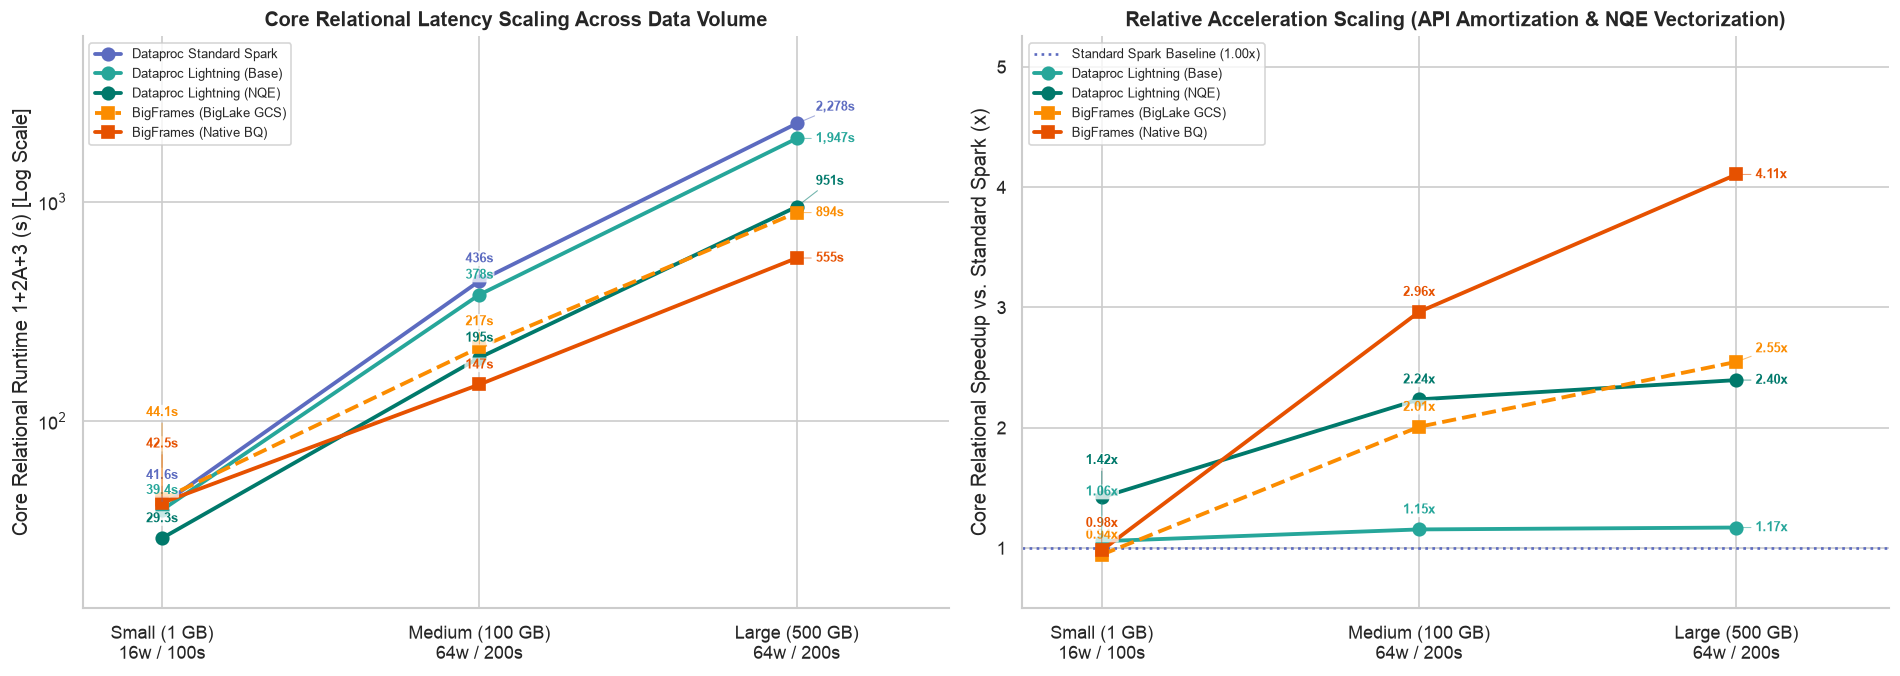

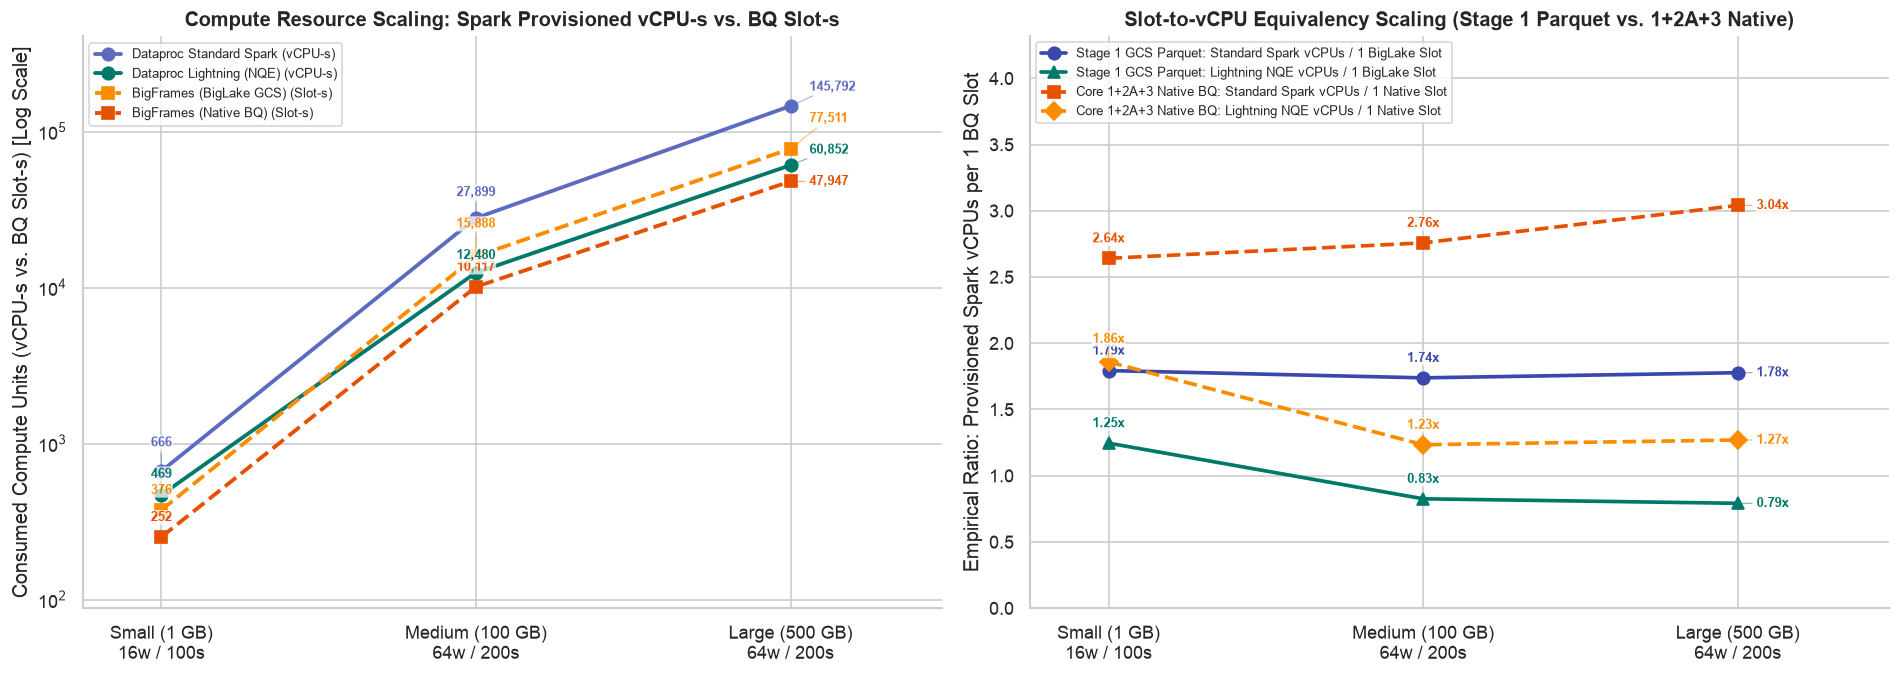

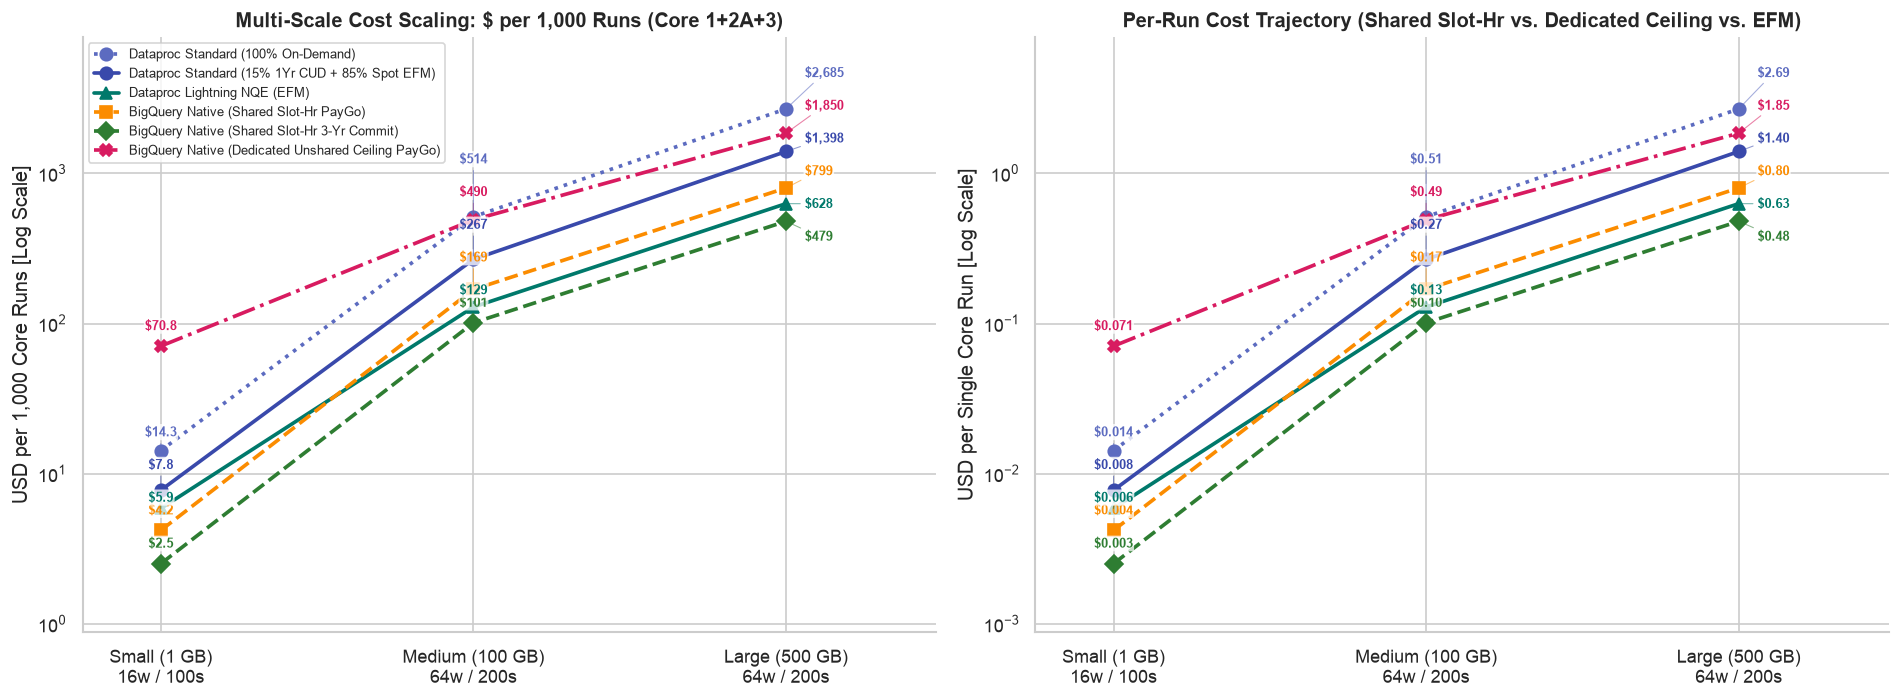

In [5]:
# ==============================================================================
# 4B. MULTI-SCALE SCALING CURVES (RUNTIME/SPEEDUP, EQUIVALENCY & COST)
#     Supports 1-, 2-, and 3-scale telemetry cleanly without axis failures.
# ==============================================================================
from collections import defaultdict

n_scales = len(available_scales)
x_idx = np.arange(n_scales)
x_tick_labels = [
    SCALE_SHORT_LABELS.get(
        s,
        f"{s}\n{SCALE_TOPOLOGIES[s]['worker_vcpus']}w / {SCALE_TOPOLOGIES[s]['bq_slot_cap']}s",
    )
    for s in available_scales
]
single_scale_note = " (Single-Scale View; run 100g/500g for multi-point curves)" if n_scales == 1 else ""
x_limits = (-0.5, 0.5) if n_scales == 1 else (-0.25, n_scales - 0.52)


def _annotate_spaced(ax, buckets: dict, is_log: bool = False, min_gap_frac: float = 0.055) -> None:
    """Place point labels without vertical collisions by pushing dense labels cleanly apart."""
    y_min, y_max = ax.get_ylim()
    to_norm = (
        (lambda y: (math.log10(y) - math.log10(max(y_min, 1e-9))) / max(1e-9, math.log10(max(y_max, 1e-8) / max(y_min, 1e-9))))
        if is_log
        else (lambda y: (y - y_min) / max(1e-9, y_max - y_min))
    )
    from_norm = (
        (lambda n: 10.0 ** (math.log10(max(y_min, 1e-9)) + n * math.log10(max(y_max, 1e-8) / max(y_min, 1e-9))))
        if is_log
        else (lambda n: y_min + n * (y_max - y_min))
    )
    for xi, items in buckets.items():
        if not items:
            continue
        sorted_items = sorted(items, key=lambda t: t[0])
        norms = [to_norm(t[0]) for t in sorted_items]
        placed = list(norms)
        for i in range(1, len(placed)):
            if placed[i] - placed[i - 1] < min_gap_frac:
                placed[i] = placed[i - 1] + min_gap_frac
        if placed[-1] > 0.94:
            shift = placed[-1] - 0.94
            placed = [max(0.03, p - shift) for p in placed]
            for i in range(len(placed) - 2, -1, -1):
                if placed[i + 1] - placed[i] < min_gap_frac:
                    placed[i] = max(0.03, placed[i + 1] - min_gap_frac)

        is_rightmost = n_scales > 1 and xi == n_scales - 1
        for (yi, lbl, color), n_raw, n_adj in zip(sorted_items, norms, placed):
            moved = abs(n_adj - n_raw) > 0.015
            if is_rightmost:
                tx, ty, ha, va = xi + 0.06, from_norm(n_adj), "left", "center"
                ax.annotate(
                    lbl,
                    xy=(xi, yi),
                    xytext=(tx, ty),
                    textcoords="data",
                    xycoords="data",
                    ha=ha,
                    va=va,
                    fontsize=7.5,
                    color=color,
                    fontweight="bold",
                    bbox={"boxstyle": "round,pad=0.1", "facecolor": "white", "edgecolor": "none", "alpha": 0.78},
                    arrowprops={"arrowstyle": "-", "lw": 0.65, "color": color, "alpha": 0.55},
                )
            elif moved:
                ax.annotate(
                    lbl,
                    xy=(xi, yi),
                    xytext=(xi, from_norm(n_adj)),
                    textcoords="data",
                    xycoords="data",
                    ha="center",
                    va="center",
                    fontsize=7.5,
                    color=color,
                    fontweight="bold",
                    bbox={"boxstyle": "round,pad=0.1", "facecolor": "white", "edgecolor": "none", "alpha": 0.78},
                    arrowprops={"arrowstyle": "-", "lw": 0.65, "color": color, "alpha": 0.55},
                )
            else:
                ax.annotate(
                    lbl,
                    xy=(xi, yi),
                    xytext=(0, 8),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=7.5,
                    color=color,
                    fontweight="bold",
                    bbox={"boxstyle": "round,pad=0.08", "facecolor": "white", "edgecolor": "none", "alpha": 0.75},
                )


# --- CHART 4A: Core Relational Runtime (1+2A+3) & Speedup vs Standard Spark ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))

all_core_vals = multi_scale_df["core_rel_sec"].dropna()
use_log_rt = n_scales > 1 and not all_core_vals.empty and (all_core_vals.max() / max(1e-6, all_core_vals.min())) >= 6.0
rt_buckets = defaultdict(list)

for eng in ENGINE_ORDER:
    sub = multi_scale_df[multi_scale_df["engine_variant"] == eng].set_index("scale_preset").reindex(available_scales)
    vals = sub["core_rel_sec"].values.astype(float)
    valid = np.isfinite(vals)
    if not valid.any():
        continue
    ls = "--" if eng == "bigframes_biglake_gcs" else "-"
    marker = "s" if eng.startswith("bigframes") else "o"
    ax1.plot(
        x_idx[valid], vals[valid], marker=marker, markersize=7.5, linewidth=2.3,
        linestyle=ls, color=ENGINE_PALETTE[eng], label=ENGINE_LABELS[eng],
    )
    for xi, yi in zip(x_idx[valid], vals[valid]):
        rt_buckets[int(xi)].append((yi, f"{yi:,.0f}s" if yi >= 100 else f"{yi:.1f}s", ENGINE_PALETTE[eng]))

if use_log_rt:
    ax1.set_yscale("log")
    ax1.set_ylim(max(1.0, float(all_core_vals.min()) * 0.48), float(all_core_vals.max()) * 2.5)
else:
    ax1.set_ylim(0, float(all_core_vals.max()) * 1.32 if not all_core_vals.empty else 10.0)
ax1.set_xlim(*x_limits)
_annotate_spaced(ax1, rt_buckets, is_log=use_log_rt)
ax1.set_xticks(x_idx)
ax1.set_xticklabels(x_tick_labels)
ax1.set_ylabel("Core Relational Runtime 1+2A+3 (s)" + (" [Log Scale]" if use_log_rt else ""))
ax1.set_title(f"Core Relational Latency Scaling Across Data Volume{single_scale_note}")
ax1.legend(fontsize=8, loc="upper left", frameon=True)

# Right panel: Speedup multiplier (x vs Spark Standard) across scales
ax2.axhline(1.0, color=ENGINE_PALETTE["spark_standard"], linestyle=":", linewidth=1.6, label="Standard Spark Baseline (1.00x)")
max_sp_x = 1.5
sp_buckets = defaultdict(list)
for eng in [e for e in ENGINE_ORDER if e != "spark_standard"]:
    sub = multi_scale_df[multi_scale_df["engine_variant"] == eng].set_index("scale_preset").reindex(available_scales)
    vals = sub["speedup_vs_std_x"].values.astype(float)
    valid = np.isfinite(vals)
    if not valid.any():
        continue
    max_sp_x = max(max_sp_x, float(np.nanmax(vals[valid])))
    ls = "--" if eng == "bigframes_biglake_gcs" else "-"
    marker = "s" if eng.startswith("bigframes") else "o"
    ax2.plot(
        x_idx[valid], vals[valid], marker=marker, markersize=7.5, linewidth=2.3,
        linestyle=ls, color=ENGINE_PALETTE[eng], label=ENGINE_LABELS[eng],
    )
    for xi, yi in zip(x_idx[valid], vals[valid]):
        sp_buckets[int(xi)].append((yi, f"{yi:.2f}x", ENGINE_PALETTE[eng]))

ax2.set_xlim(*x_limits)
ax2.set_ylim(0.5, max_sp_x * 1.28)
_annotate_spaced(ax2, sp_buckets, is_log=False)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(x_tick_labels)
ax2.set_ylabel("Core Relational Speedup vs. Standard Spark (x)")
ax2.set_title("Relative Acceleration Scaling (API Amortization & NQE Vectorization)")
ax2.legend(fontsize=8, loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

# --- CHART 4B: Compute Resource & Slot-to-vCPU Equivalency Scaling Curve ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))

comp_buckets = defaultdict(list)
for eng, col, suffix, marker, ls in [
    ("spark_standard", "vcpu_seconds", "vCPU-s", "o", "-"),
    ("spark_lightning_nqe", "vcpu_seconds", "vCPU-s", "o", "-"),
    ("bigframes_biglake_gcs", "bq_slot_seconds", "Slot-s", "s", "--"),
    ("bigframes_native_bq", "bq_slot_seconds", "Slot-s", "s", "--"),
]:
    sub = multi_scale_df[multi_scale_df["engine_variant"] == eng].set_index("scale_preset").reindex(available_scales)
    vals = sub[col].values.astype(float)
    valid = np.isfinite(vals)
    if valid.any():
        ax1.plot(
            x_idx[valid], vals[valid], marker=marker, markersize=7.5, linewidth=2.3,
            linestyle=ls, color=ENGINE_PALETTE[eng], label=f"{ENGINE_LABELS[eng]} ({suffix})",
        )
        for xi, yi in zip(x_idx[valid], vals[valid]):
            comp_buckets[int(xi)].append((yi, f"{yi:,.0f}", ENGINE_PALETTE[eng]))

comp_all = pd.concat([multi_scale_df["vcpu_seconds"].dropna(), multi_scale_df["bq_slot_seconds"].dropna()])
use_log_comp = n_scales > 1 and not comp_all.empty and (comp_all.max() / max(1e-6, comp_all.min())) >= 6.0
if use_log_comp:
    ax1.set_yscale("log")
    ax1.set_ylim(max(1.0, float(comp_all.min()) * 0.35), float(comp_all.max()) * 2.8)
elif not comp_all.empty:
    ax1.set_ylim(0, float(comp_all.max()) * 1.32)
ax1.set_xlim(*x_limits)
_annotate_spaced(ax1, comp_buckets, is_log=use_log_comp)
ax1.set_xticks(x_idx)
ax1.set_xticklabels(x_tick_labels)
ax1.set_ylabel("Consumed Compute Units (vCPU-s vs. BQ Slot-s)" + (" [Log Scale]" if use_log_comp else ""))
ax1.set_title("Compute Resource Scaling: Spark Provisioned vCPU-s vs. BQ Slot-s")
ax1.legend(fontsize=8, loc="upper left", frameon=True)

# Right panel: Empirical Slot-to-vCPU Equivalency Curves (Stage 1 GCS & Core 1+2A+3 Native BQ)
eq_series = [
    ("spark_standard", "s1_1slot_eq_vcpus", "Stage 1 GCS Parquet: Standard Spark vCPUs / 1 BigLake Slot", "#3949AB", "-", "o"),
    ("spark_lightning_nqe", "s1_1slot_eq_vcpus", "Stage 1 GCS Parquet: Lightning NQE vCPUs / 1 BigLake Slot", "#00796B", "-", "^"),
    ("spark_standard", "core_1slot_eq_vcpus", "Core 1+2A+3 Native BQ: Standard Spark vCPUs / 1 Native Slot", "#E65100", "--", "s"),
    ("spark_lightning_nqe", "core_1slot_eq_vcpus", "Core 1+2A+3 Native BQ: Lightning NQE vCPUs / 1 Native Slot", "#FB8C00", "--", "D"),
]
max_eq_y = 2.5
eq_buckets = defaultdict(list)
for eng, col, lbl, color, ls, marker in eq_series:
    sub = multi_scale_df[multi_scale_df["engine_variant"] == eng].set_index("scale_preset").reindex(available_scales)
    vals = sub[col].values.astype(float)
    valid = np.isfinite(vals)
    if not valid.any():
        continue
    max_eq_y = max(max_eq_y, float(np.nanmax(vals[valid])))
    ax2.plot(x_idx[valid], vals[valid], marker=marker, markersize=7.5, linewidth=2.2, linestyle=ls, color=color, label=lbl)
    for xi, yi in zip(x_idx[valid], vals[valid]):
        eq_buckets[int(xi)].append((yi, f"{yi:.2f}x", color))

ax2.set_xlim(*x_limits)
ax2.set_ylim(0, max_eq_y * 1.42)
_annotate_spaced(ax2, eq_buckets, is_log=False)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(x_tick_labels)
ax2.set_ylabel("Empirical Ratio: Provisioned Spark vCPUs per 1 BQ Slot")
ax2.set_title("Slot-to-vCPU Equivalency Scaling (Stage 1 Parquet vs. 1+2A+3 Native)")
ax2.legend(fontsize=7.5, loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

# --- CHART 4C: Multi-Scale Cost Scaling Curve ($ per 1,000 Runs & $ per Run) ---
cost_series_1k = [
    ("spark_standard", "dp_1k_ondemand_usd", "Dataproc Standard (100% On-Demand)", "#5C6BC0", ":", "o"),
    ("spark_standard", "dp_1k_efm_usd", "Dataproc Standard (15% 1Yr CUD + 85% Spot EFM)", "#3949AB", "-", "o"),
    ("spark_lightning_nqe", "dp_1k_efm_usd", "Dataproc Lightning NQE (EFM)", "#00796B", "-", "^"),
    ("bigframes_native_bq", "bq_1k_shared_paygo_usd", "BigQuery Native (Shared Slot-Hr PayGo)", "#FB8C00", "--", "s"),
    ("bigframes_native_bq", "bq_1k_shared_3yr_usd", "BigQuery Native (Shared Slot-Hr 3-Yr Commit)", "#2E7D32", "--", "D"),
    ("bigframes_native_bq", "bq_1k_dedicated_ceil_usd", "BigQuery Native (Dedicated Unshared Ceiling PayGo)", "#D81B60", "-.", "X"),
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.0))
plotted_costs = []
c1k_buckets = defaultdict(list)
c1_buckets = defaultdict(list)
for eng, col, lbl, color, ls, marker in cost_series_1k:
    sub = multi_scale_df[multi_scale_df["engine_variant"] == eng].set_index("scale_preset").reindex(available_scales)
    vals_1k = sub[col].values.astype(float)
    valid = np.isfinite(vals_1k)
    if not valid.any():
        continue
    plotted_costs.extend(vals_1k[valid].tolist())
    vals_1run = vals_1k / 1000.0
    ax1.plot(x_idx[valid], vals_1k[valid], marker=marker, markersize=7.5, linewidth=2.2, linestyle=ls, color=color, label=lbl)
    ax2.plot(x_idx[valid], vals_1run[valid], marker=marker, markersize=7.5, linewidth=2.2, linestyle=ls, color=color, label=lbl)
    for xi, y1k, y1 in zip(x_idx[valid], vals_1k[valid], vals_1run[valid]):
        c1k_buckets[int(xi)].append((y1k, f"${y1k:,.0f}" if y1k >= 100 else f"${y1k:.1f}", color))
        c1_buckets[int(xi)].append((y1, f"${y1:.2f}" if y1 >= 0.1 else f"${y1:.3f}", color))

use_log_cost = n_scales > 1 and plotted_costs and (max(plotted_costs) / max(1e-6, min(plotted_costs))) >= 6.0
for ax, unit_lbl, mult, buckets in [
    (ax1, "USD per 1,000 Core Runs", 1.0, c1k_buckets),
    (ax2, "USD per Single Core Run", 0.001, c1_buckets),
]:
    if use_log_cost and plotted_costs:
        ax.set_yscale("log")
        ax.set_ylim(max(1e-4, min(plotted_costs) * mult * 0.35), max(plotted_costs) * mult * 3.0)
    elif plotted_costs:
        ax.set_ylim(0, max(plotted_costs) * mult * 1.32)
    ax.set_xlim(*x_limits)
    _annotate_spaced(ax, buckets, is_log=bool(use_log_cost))
    ax.set_xticks(x_idx)
    ax.set_xticklabels(x_tick_labels)
    ax.set_ylabel(unit_lbl + (" [Log Scale]" if use_log_cost else ""))

ax1.set_title("Multi-Scale Cost Scaling: $ per 1,000 Runs (Core 1+2A+3)")
ax2.set_title("Per-Run Cost Trajectory (Shared Slot-Hr vs. Dedicated Ceiling vs. EFM)")
ax1.legend(fontsize=7.5, loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


## 5. Single-Scale Deep-Dive (`PRIMARY_DEEP_DIVE_SCALE`): Stage Latency Breakdown & Speedups

Deep-dive analysis automatically targets the largest loaded scale preset (**`large_500g`** when all 3 scales are present; customizable via `TARGET_SCALE_PRESET`). We separate **Core Relational ELT (`Stage 1 + Stage 2A + Stage 3`)** from **Scalar Python UDF (`Stage 2B`)** to measure pure columnar acceleration cleanly alongside total pipeline runtime.


Deep-Dive Scale: large_500g | Spark: 64w vCPUs (4 x n2d-standard-16, 8 SSDs) | BigQuery: 200 slots


stage_id,stage1_bronze_to_silver,stage2a_silver_vectorized,stage2b_silver_udf,stage3_silver_to_gold,relational_total_sec,udf_stage2b_sec,full_total_sec,rel_speedup_vs_ref,full_speedup_vs_ref
engine_variant,,,,,,,,,
Dataproc Standard Spark,845.01 s,369.52 s,246.50 s,1063.47 s,2278.00 s,246.50 s,2524.50 s,1.00x,1.00x
Dataproc Lightning (Base),730.71 s,312.28 s,232.60 s,903.91 s,1946.90 s,232.60 s,2179.50 s,1.17x,1.16x
Dataproc Lightning (NQE),376.22 s,131.94 s,270.14 s,442.66 s,950.82 s,270.14 s,1220.96 s,2.40x,2.07x
BigFrames (BigLake GCS),357.17 s,114.79 s,85.25 s,422.22 s,894.18 s,85.25 s,979.43 s,2.55x,2.58x
BigFrames (Native BQ),216.94 s,77.35 s,61.50 s,260.60 s,554.89 s,61.50 s,616.39 s,4.11x,4.10x


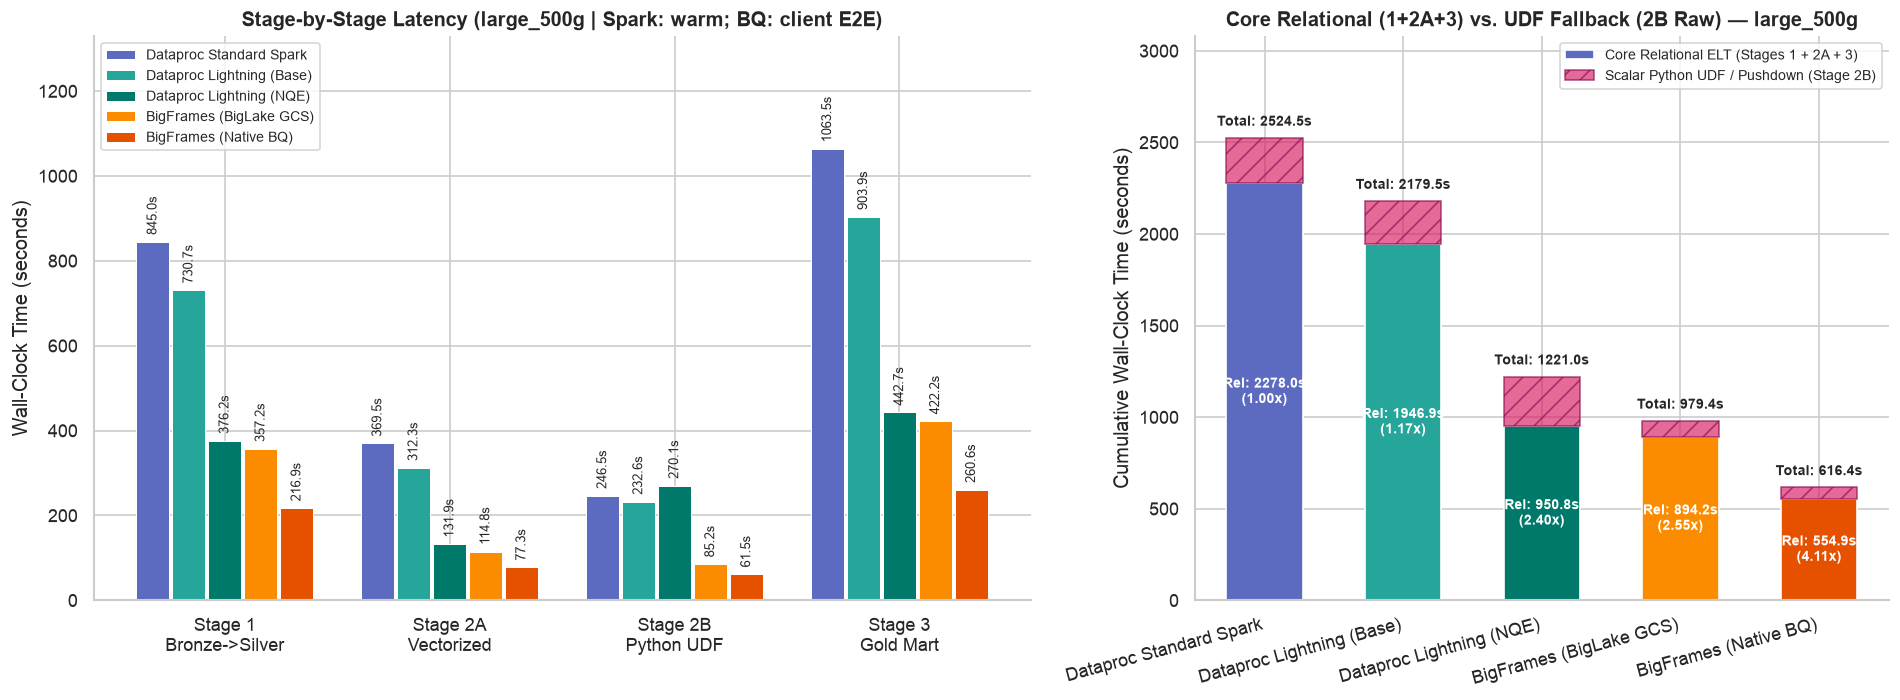

In [6]:
# ==============================================================================
# 5. SINGLE-SCALE DEEP-DIVE: STAGE LATENCY BREAKDOWN & GROUPED/STACKED CHARTS
# ==============================================================================
lat_pivot = df.pivot(index="engine_variant", columns="stage_id", values="wall_clock_sec").reindex(
    index=present_engines, columns=present_stages
).fillna(0.0)

core_cols = [s for s in CORE_RELATIONAL_STAGES if s in lat_pivot.columns]
lat_summary = lat_pivot.copy()
lat_summary["relational_total_sec"] = lat_summary[core_cols].sum(axis=1)
lat_summary["udf_stage2b_sec"] = lat_summary["stage2b_silver_udf"] if "stage2b_silver_udf" in lat_summary.columns else 0.0
lat_summary["full_total_sec"] = lat_summary["relational_total_sec"] + lat_summary["udf_stage2b_sec"]

std_rel = lat_summary.loc[ref_engine, "relational_total_sec"]
std_full = lat_summary.loc[ref_engine, "full_total_sec"]
lat_summary["rel_speedup_vs_ref"] = std_rel / lat_summary["relational_total_sec"]
lat_summary["full_speedup_vs_ref"] = std_full / lat_summary["full_total_sec"]

print(
    f"Deep-Dive Scale: {PRIMARY_DEEP_DIVE_SCALE} | Spark: {CLUSTER_TOPOLOGY['worker_vcpus']}w vCPUs "
    f"({CLUSTER_TOPOLOGY['num_workers']} x {CLUSTER_TOPOLOGY['worker_machine_type']}, {CLUSTER_TOPOLOGY['worker_local_ssds']} SSDs) "
    f"| BigQuery: {CLUSTER_TOPOLOGY['bq_slot_cap']} slots"
)
show_table(
    lat_summary.rename(index=ENGINE_LABELS),
    {
        **{s: "{:.2f} s" for s in present_stages},
        "relational_total_sec": "{:.2f} s",
        "udf_stage2b_sec": "{:.2f} s",
        "full_total_sec": "{:.2f} s",
        "rel_speedup_vs_ref": "{:.2f}x",
        "full_speedup_vs_ref": "{:.2f}x",
    },
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.35, 1.0]})

x = np.arange(len(present_stages))
bar_w = 0.8 / max(1, len(present_engines))
max_stage_lat = float(lat_pivot.values.max()) if lat_pivot.size else 1.0
for idx, eng in enumerate(present_engines):
    vals = [float(lat_pivot.loc[eng, s]) for s in present_stages]
    offset = (idx - (len(present_engines) - 1) / 2.0) * bar_w
    bars = ax1.bar(
        x + offset,
        vals,
        width=bar_w * 0.92,
        label=ENGINE_LABELS[eng],
        color=ENGINE_PALETTE[eng],
        edgecolor="white",
        linewidth=0.6,
    )
    for bar, v in zip(bars, vals):
        ax1.text(
            bar.get_x() + bar.get_width() / 2.0,
            v + max(max_stage_lat * 0.015, 0.3),
            f"{v:.1f}s",
            ha="center",
            va="bottom",
            fontsize=7.5,
            rotation=90 if len(present_engines) >= 4 else 0,
        )

ax1.set_xticks(x)
ax1.set_xticklabels([STAGE_SHORT_LABELS.get(s, s) for s in present_stages])
ax1.set_ylabel("Wall-Clock Time (seconds)")
ax1.set_title(f"Stage-by-Stage Latency ({PRIMARY_DEEP_DIVE_SCALE} | Spark: warm; BQ: client E2E)")
ax1.set_ylim(0, max_stage_lat * 1.25)
ax1.legend(frameon=True, fontsize=8.5, loc="upper left")

rel_vals = lat_summary["relational_total_sec"].values
udf_vals = lat_summary["udf_stage2b_sec"].values
x2 = np.arange(len(present_engines))

ax2.bar(
    x2,
    rel_vals,
    width=0.55,
    color=[ENGINE_PALETTE[e] for e in present_engines],
    label="Core Relational ELT (Stages 1 + 2A + 3)",
    edgecolor="white",
)
if np.any(udf_vals > 0):
    ax2.bar(
        x2,
        udf_vals,
        width=0.55,
        bottom=rel_vals,
        color="#D81B60",
        alpha=0.65,
        hatch="//",
        edgecolor="#880E4F",
        label="Scalar Python UDF / Pushdown (Stage 2B)",
    )

max_tot = float((rel_vals + udf_vals).max())
for idx, eng in enumerate(present_engines):
    r_v = rel_vals[idx]
    u_v = udf_vals[idx]
    tot_v = r_v + u_v
    sp = lat_summary.loc[eng, "rel_speedup_vs_ref"]
    if r_v > max_tot * 0.08:
        ax2.text(idx, r_v / 2.0, f"Rel: {r_v:.1f}s\n({sp:.2f}x)", ha="center", va="center", color="white", fontweight="bold", fontsize=8.5)
    ax2.text(idx, tot_v + max_tot * 0.02, f"Total: {tot_v:.1f}s", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax2.set_xticks(x2)
ax2.set_xticklabels([ENGINE_LABELS[e] for e in present_engines], rotation=15, ha="right")
ax2.set_ylabel("Cumulative Wall-Clock Time (seconds)")
ax2.set_title(f"Core Relational (1+2A+3) vs. UDF Fallback (2B Raw) — {PRIMARY_DEEP_DIVE_SCALE}")
ax2.set_ylim(0, max_tot * 1.22)
ax2.legend(frameon=True, fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()


## 6. Single-Scale Deep-Dive: Execution Timeline Waterfall (Epoch-Normalized Gantt)

Aligns every engine's Stage 1 start to `t = 0s` using raw `start_epoch_sec` / `end_epoch_sec` telemetry on `PRIMARY_DEEP_DIVE_SCALE`, separating true compute spans from validation pauses between stages.


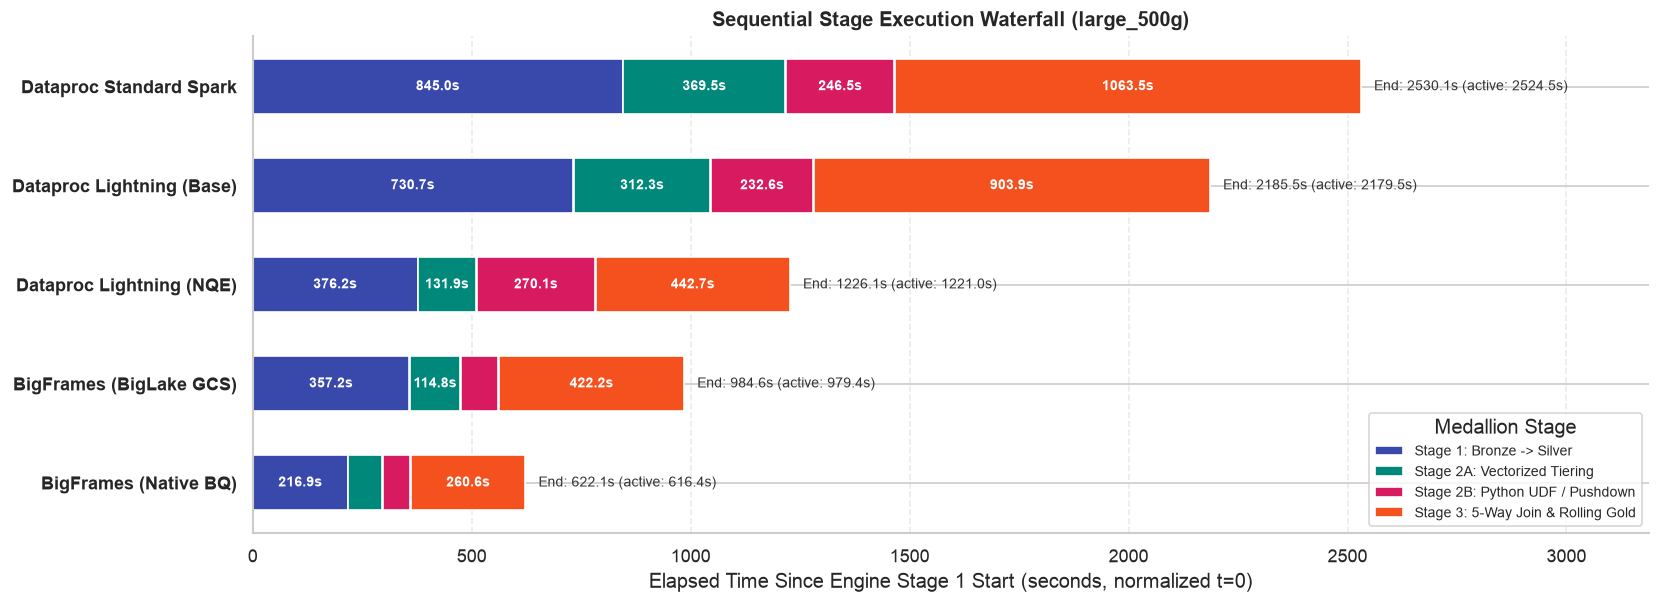

In [7]:
# ==============================================================================
# 6. NORMALIZED EXECUTION TIMELINE GANTT / WATERFALL CHART
# ==============================================================================
gantt_df = df.copy()
t0_by_engine = gantt_df.groupby("engine_variant")["start_epoch_sec"].transform("min")
gantt_df["rel_start_sec"] = gantt_df["start_epoch_sec"] - t0_by_engine
gantt_df["rel_end_sec"] = gantt_df["end_epoch_sec"] - t0_by_engine
gantt_df["stage_elapsed_sec"] = gantt_df["end_epoch_sec"] - gantt_df["start_epoch_sec"]

inter_gaps = []
for eng in present_engines:
    sub = gantt_df[gantt_df["engine_variant"] == eng].sort_values("start_epoch_sec")
    gaps = sub["start_epoch_sec"].iloc[1:].values - sub["end_epoch_sec"].iloc[:-1].values
    if len(gaps) > 0:
        inter_gaps.append(float(np.max(gaps)))
max_gap = max(inter_gaps) if inter_gaps else 0.0
if max_gap > 60.0:
    print(
        f"Note: Max inter-stage gap of {max_gap:.1f}s detected (typical when running cells interactively). "
        "Showing true normalized epoch offsets; see Section 5 for pure compute time."
    )

fig, ax = plt.subplots(figsize=(14, 5.2))
y_positions = np.arange(len(present_engines))
max_rel_end = float(gantt_df["rel_end_sec"].max())

plotted_stages = set()
for y_idx, eng in enumerate(present_engines):
    sub = gantt_df[gantt_df["engine_variant"] == eng].sort_values("rel_start_sec")
    for _, row in sub.iterrows():
        stg = row["stage_id"]
        label = STAGE_LABELS[stg] if stg not in plotted_stages else None
        plotted_stages.add(stg)
        left = float(row["rel_start_sec"])
        width = float(row["stage_elapsed_sec"])
        ax.barh(
            y_idx,
            width,
            left=left,
            height=0.56,
            color=STAGE_COLORS[stg],
            edgecolor="white",
            linewidth=1.0,
            label=label,
        )
        if width >= max_rel_end * 0.045:
            ax.text(
                left + width / 2.0,
                y_idx,
                f"{width:.1f}s",
                ha="center",
                va="center",
                color="white",
                fontweight="bold",
                fontsize=8.5,
            )

    total_span = float(sub["rel_end_sec"].max())
    compute_sum = float(sub["wall_clock_sec"].sum())
    ax.text(
        total_span + max_rel_end * 0.012,
        y_idx,
        f"End: {total_span:.1f}s (active: {compute_sum:.1f}s)",
        va="center",
        ha="left",
        fontsize=8.5,
        color="#333333",
    )

ax.set_yticks(y_positions)
ax.set_yticklabels([ENGINE_LABELS[e] for e in present_engines], fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Elapsed Time Since Engine Stage 1 Start (seconds, normalized t=0)")
ax.set_title(f"Sequential Stage Execution Waterfall ({PRIMARY_DEEP_DIVE_SCALE})")
ax.set_xlim(0, max_rel_end * 1.26)
ax.legend(title="Medallion Stage", loc="lower right", frameon=True, fontsize=8.5)
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## 7. Single-Scale Deep-Dive: Empirical Compute Equivalency (`1 BQ Slot ≈ X Spark vCPUs`) & Storage Comparison

Two explicit baselines are reported on `PRIMARY_DEEP_DIVE_SCALE` so storage format is never conflated with engine compute:
- **Stage 1 Only vs. `bigframes_biglake_gcs`:** Both Spark and BigFrames read identical Bronze GCS Parquet (`0%` native Capacitor advantage).
- **Stages `1 + 2A + 3` vs. `bigframes_native_bq`:** End-to-end Native Capacitor table layout vs. GCS Parquet Dataproc Spark.



--- Ratio: Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. BigLake Pass (large_500g | Identical GCS Parquet in Stage 1) ---


,bq_slot_sec,bq_avg_active_slots,bq_mib_processed,spark_standard,spark_lightning_base,spark_lightning_nqe
stage_group,,,,,,
stage1_bronze_to_silver,"30,429.7 slot-s",85.2 slots,"199,556.4 MiB",1.78 vCPU/slot,1.54 vCPU/slot,0.79 vCPU/slot
stage2a_silver_vectorized,"8,860.7 slot-s",77.2 slots,"140,190.1 MiB",2.67 vCPU/slot,2.26 vCPU/slot,0.95 vCPU/slot
stage2b_silver_udf,"6,495.1 slot-s",76.2 slots,"140,190.1 MiB",2.43 vCPU/slot,2.29 vCPU/slot,2.66 vCPU/slot
stage3_silver_to_gold,"38,220.1 slot-s",90.5 slots,"220,298.8 MiB",1.78 vCPU/slot,1.51 vCPU/slot,0.74 vCPU/slot
CORE_RELATIONAL (1+2A+3),"77,510.5 slot-s",86.7 slots,"560,045.2 MiB",1.88 vCPU/slot,1.61 vCPU/slot,0.79 vCPU/slot
ALL_STAGES,"84,005.6 slot-s",85.8 slots,"700,235.4 MiB",1.92 vCPU/slot,1.66 vCPU/slot,0.93 vCPU/slot



--- Ratio: Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. Native BQ Capacitor Pass (large_500g) ---


,bq_slot_sec,bq_avg_active_slots,bq_mib_processed,spark_standard,spark_lightning_base,spark_lightning_nqe
stage_group,,,,,,
stage1_bronze_to_silver,"17,713.5 slot-s",81.7 slots,"113,964.1 MiB",3.05 vCPU/slot,2.64 vCPU/slot,1.36 vCPU/slot
stage2a_silver_vectorized,"6,148.0 slot-s",79.5 slots,"87,738.0 MiB",3.85 vCPU/slot,3.25 vCPU/slot,1.37 vCPU/slot
stage2b_silver_udf,"4,364.2 slot-s",71.0 slots,"87,738.0 MiB",3.61 vCPU/slot,3.41 vCPU/slot,3.96 vCPU/slot
stage3_silver_to_gold,"24,085.9 slot-s",92.4 slots,"129,222.9 MiB",2.83 vCPU/slot,2.40 vCPU/slot,1.18 vCPU/slot
CORE_RELATIONAL (1+2A+3),"47,947.4 slot-s",86.4 slots,"330,925.0 MiB",3.04 vCPU/slot,2.60 vCPU/slot,1.27 vCPU/slot
ALL_STAGES,"52,311.6 slot-s",84.9 slots,"418,663.0 MiB",3.09 vCPU/slot,2.67 vCPU/slot,1.49 vCPU/slot



--- BigLake Parquet vs. Native BQ Capacitor Delta (large_500g) ---


,storage_comparison_scope,biglake_slot_sec,native_slot_sec,slot_ms_delta_pct,biglake_mib,native_mib,io_bytes_delta_pct
stage_id,,,,,,,
stage1_bronze_to_silver,Bronze Read: BigLake Parquet vs. Capacitor (True Storage Delta),"30,429.7 s","17,713.5 s",+41.8%,"199,556.4 MiB","113,964.1 MiB",+42.9%
stage2a_silver_vectorized,Silver Read: Native BQ in Both Passes (Run Variance Only),"8,860.7 s","6,148.0 s",+30.6%,"140,190.1 MiB","87,738.0 MiB",+37.4%
stage2b_silver_udf,Silver Read: Native BQ in Both Passes (Run Variance Only),"6,495.1 s","4,364.2 s",+32.8%,"140,190.1 MiB","87,738.0 MiB",+37.4%
stage3_silver_to_gold,Mixed: Native BQ Silver + BigLake vs. Native Bronze Dims,"38,220.1 s","24,085.9 s",+37.0%,"220,298.8 MiB","129,222.9 MiB",+41.3%


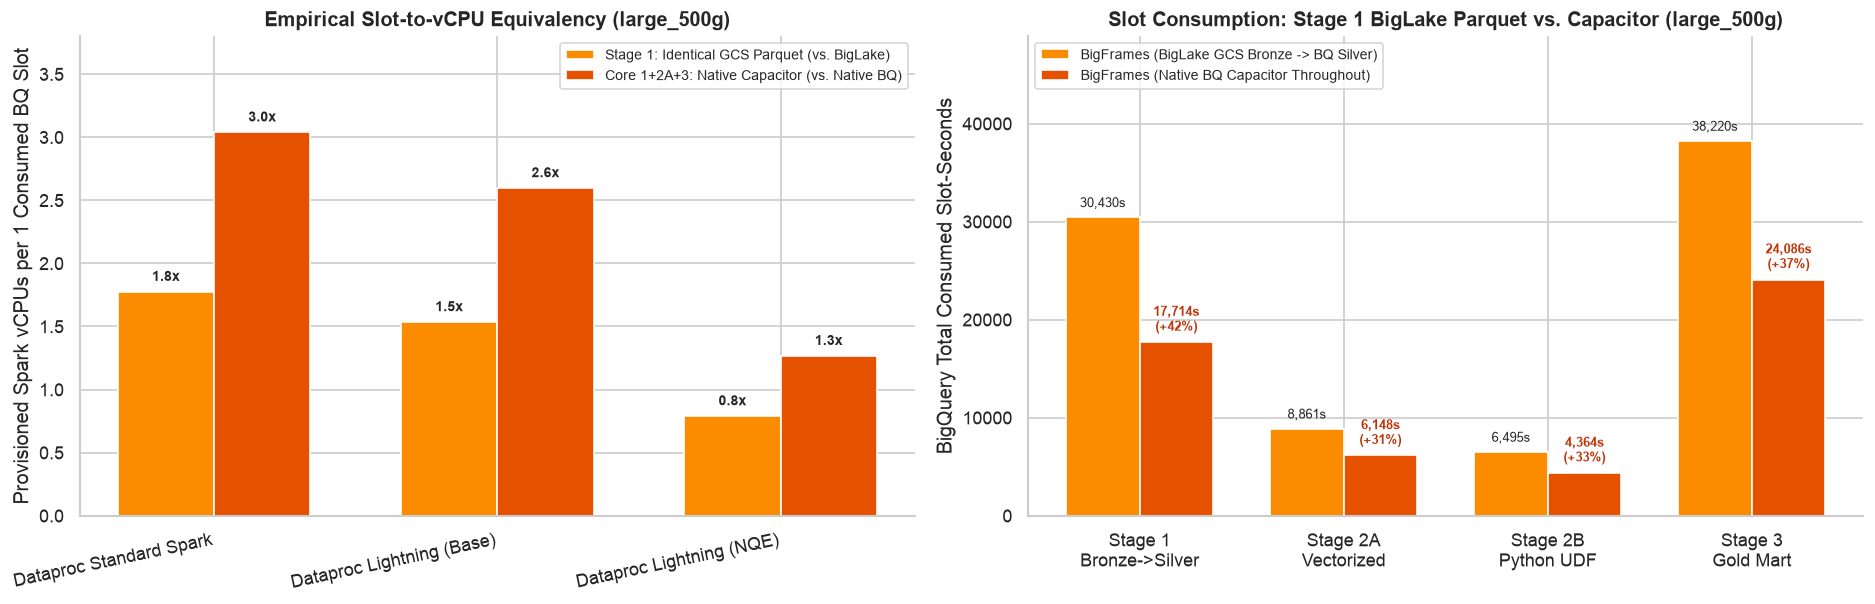

In [8]:
# ==============================================================================
# 7. EMPIRICAL COMPUTE EQUIVALENCY TABLE & STORAGE COMPARISON VISUAL
# ==============================================================================
spark_variants = [e for e in ["spark_standard", "spark_lightning_base", "spark_lightning_nqe"] if e in present_engines]
bq_variants = [e for e in ["bigframes_biglake_gcs", "bigframes_native_bq"] if e in present_engines]

if spark_variants and bq_variants:
    agg_groups = {
        **{s: [s] for s in present_stages},
        "CORE_RELATIONAL (1+2A+3)": [s for s in CORE_RELATIONAL_STAGES if s in present_stages],
        "ALL_STAGES": present_stages,
    }

    eq_records = []
    for group_name, stg_list in agg_groups.items():
        sub = df[df["stage_id"].isin(stg_list)]
        for bq_eng in bq_variants:
            bq_sub = sub[sub["engine_variant"] == bq_eng]
            if bq_sub.empty:
                continue
            bq_slot_s = float(bq_sub["bq_slot_seconds"].sum())
            bq_wall_s = float(bq_sub["wall_clock_sec"].sum())
            bq_avg_slots = bq_slot_s / bq_wall_s if bq_wall_s > 0 else np.nan
            bq_mib = float(bq_sub["bq_mib_processed"].sum())

            for sp_eng in spark_variants:
                sp_sub = sub[sub["engine_variant"] == sp_eng]
                if sp_sub.empty:
                    continue
                sp_vcpu_s = float(sp_sub["vcpu_seconds"].sum())
                spark_vcpus_per_bq_slot = sp_vcpu_s / bq_slot_s if bq_slot_s > 0 else np.nan
                bq_slots_per_spark_vcpu = bq_slot_s / sp_vcpu_s if sp_vcpu_s > 0 else np.nan
                eq_records.append({
                    "stage_group": group_name,
                    "bq_baseline": bq_eng,
                    "spark_variant": sp_eng,
                    "spark_vcpu_sec": sp_vcpu_s,
                    "bq_slot_sec": bq_slot_s,
                    "bq_avg_active_slots": bq_avg_slots,
                    "bq_mib_processed": bq_mib,
                    "spark_vcpus_per_1_bq_slot": spark_vcpus_per_bq_slot,
                    "bq_slots_per_1_spark_vcpu": bq_slots_per_spark_vcpu,
                })

    eq_df = pd.DataFrame(eq_records)

    for bq_eng, title_suffix in [
        (
            "bigframes_biglake_gcs",
            f"Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. BigLake Pass ({PRIMARY_DEEP_DIVE_SCALE} | Identical GCS Parquet in Stage 1)",
        ),
        (
            "bigframes_native_bq",
            f"Provisioned Spark vCPU-s / Consumed BQ Slot-s vs. Native BQ Capacitor Pass ({PRIMARY_DEEP_DIVE_SCALE})",
        ),
    ]:
        if bq_eng not in bq_variants:
            continue
        sub_eq = eq_df[eq_df["bq_baseline"] == bq_eng]
        piv = sub_eq.pivot(index="stage_group", columns="spark_variant", values="spark_vcpus_per_1_bq_slot").reindex(
            index=list(agg_groups.keys()), columns=spark_variants
        )
        bq_meta = sub_eq.drop_duplicates("stage_group").set_index("stage_group")[
            ["bq_slot_sec", "bq_avg_active_slots", "bq_mib_processed"]
        ]
        table = bq_meta.join(piv)
        print(f"\n--- Ratio: {title_suffix} ---")
        show_table(
            table,
            {
                "bq_slot_sec": "{:,.1f} slot-s",
                "bq_avg_active_slots": "{:.1f} slots",
                "bq_mib_processed": "{:,.1f} MiB",
                **{s: "{:.2f} vCPU/slot" for s in spark_variants},
            },
        )

    if {"bigframes_biglake_gcs", "bigframes_native_bq"}.issubset(set(bq_variants)):
        _scope_labels = {
            "stage1_bronze_to_silver": "Bronze Read: BigLake Parquet vs. Capacitor (True Storage Delta)",
            "stage2a_silver_vectorized": "Silver Read: Native BQ in Both Passes (Run Variance Only)",
            "stage2b_silver_udf": "Silver Read: Native BQ in Both Passes (Run Variance Only)",
            "stage3_silver_to_gold": "Mixed: Native BQ Silver + BigLake vs. Native Bronze Dims",
        }
        cap_df = df[df["engine_variant"].isin(["bigframes_biglake_gcs", "bigframes_native_bq"])].pivot(
            index="stage_id", columns="engine_variant", values=["bq_slot_seconds", "bq_mib_processed", "wall_clock_sec"]
        ).reindex(present_stages)
        cap_summary = pd.DataFrame({
            "storage_comparison_scope": [_scope_labels.get(s, s) for s in present_stages],
            "biglake_slot_sec": cap_df[("bq_slot_seconds", "bigframes_biglake_gcs")],
            "native_slot_sec": cap_df[("bq_slot_seconds", "bigframes_native_bq")],
            "slot_ms_delta_pct": (
                1.0 - cap_df[("bq_slot_seconds", "bigframes_native_bq")] / cap_df[("bq_slot_seconds", "bigframes_biglake_gcs")]
            ) * 100.0,
            "biglake_mib": cap_df[("bq_mib_processed", "bigframes_biglake_gcs")],
            "native_mib": cap_df[("bq_mib_processed", "bigframes_native_bq")],
            "io_bytes_delta_pct": (
                1.0 - cap_df[("bq_mib_processed", "bigframes_native_bq")] / cap_df[("bq_mib_processed", "bigframes_biglake_gcs")]
            ) * 100.0,
        })
        print(f"\n--- BigLake Parquet vs. Native BQ Capacitor Delta ({PRIMARY_DEEP_DIVE_SCALE}) ---")
        show_table(
            cap_summary,
            {
                "biglake_slot_sec": "{:,.1f} s",
                "native_slot_sec": "{:,.1f} s",
                "slot_ms_delta_pct": "{:+.1f}%",
                "biglake_mib": "{:,.1f} MiB",
                "native_mib": "{:,.1f} MiB",
                "io_bytes_delta_pct": "{:+.1f}%",
            },
        )

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))
        s1_eq = eq_df[eq_df["stage_group"].isin(["stage1_bronze_to_silver", "CORE_RELATIONAL (1+2A+3)"])]
        x_eq = np.arange(len(spark_variants))
        bw = 0.34
        def _eq_val(group: str, bq_eng: str, sp_eng: str) -> float:
            m = s1_eq.loc[
                (s1_eq["stage_group"] == group) & (s1_eq["bq_baseline"] == bq_eng) & (s1_eq["spark_variant"] == sp_eng),
                "spark_vcpus_per_1_bq_slot",
            ]
            return float(m.iloc[0]) if not m.empty else 0.0

        s1_bl_vals = [_eq_val("stage1_bronze_to_silver", "bigframes_biglake_gcs", sp) for sp in spark_variants]
        rel_nv_vals = [_eq_val("CORE_RELATIONAL (1+2A+3)", "bigframes_native_bq", sp) for sp in spark_variants]

        b1 = ax1.bar(x_eq - bw / 2, s1_bl_vals, width=bw, color="#FB8C00", label="Stage 1: Identical GCS Parquet (vs. BigLake)")
        b2 = ax1.bar(x_eq + bw / 2, rel_nv_vals, width=bw, color="#E65100", label="Core 1+2A+3: Native Capacitor (vs. Native BQ)")
        max_eq = max(1.0, max(s1_bl_vals + rel_nv_vals))
        for bar, v in list(zip(b1, s1_bl_vals)) + list(zip(b2, rel_nv_vals)):
            ax1.text(bar.get_x() + bar.get_width() / 2.0, v + max_eq * 0.02, f"{v:.1f}x", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
        ax1.set_xticks(x_eq)
        ax1.set_xticklabels([ENGINE_LABELS[s] for s in spark_variants], rotation=12, ha="right")
        ax1.set_ylabel("Provisioned Spark vCPUs per 1 Consumed BQ Slot")
        ax1.set_title(f"Empirical Slot-to-vCPU Equivalency ({PRIMARY_DEEP_DIVE_SCALE})")
        ax1.set_ylim(0, max_eq * 1.25)
        ax1.legend(fontsize=8.5, loc="upper right")

        x_cap = np.arange(len(present_stages))
        bw2 = 0.36
        bl_slots = cap_summary["biglake_slot_sec"].values
        nv_slots = cap_summary["native_slot_sec"].values
        ax2.bar(x_cap - bw2 / 2, bl_slots, width=bw2, color="#FB8C00", label="BigFrames (BigLake GCS Bronze -> BQ Silver)")
        ax2.bar(x_cap + bw2 / 2, nv_slots, width=bw2, color="#E65100", label="BigFrames (Native BQ Capacitor Throughout)")
        max_sl = max(float(np.max(bl_slots)), float(np.max(nv_slots)))
        for idx in range(len(present_stages)):
            delta = float(cap_summary["slot_ms_delta_pct"].iloc[idx])
            ax2.text(idx + bw2 / 2, nv_slots[idx] + max_sl * 0.02, f"{nv_slots[idx]:,.0f}s\n({delta:+.0f}%)", ha="center", va="bottom", fontsize=8, color="#BF360C", fontweight="bold")
            ax2.text(idx - bw2 / 2, bl_slots[idx] + max_sl * 0.02, f"{bl_slots[idx]:,.0f}s", ha="center", va="bottom", fontsize=8)
        ax2.set_xticks(x_cap)
        ax2.set_xticklabels([STAGE_SHORT_LABELS.get(s, s) for s in present_stages])
        ax2.set_ylabel("BigQuery Total Consumed Slot-Seconds")
        ax2.set_title(f"Slot Consumption: Stage 1 BigLake Parquet vs. Capacitor ({PRIMARY_DEEP_DIVE_SCALE})")
        ax2.set_ylim(0, max_sl * 1.28)
        ax2.legend(fontsize=8.5, loc="upper left")

        plt.tight_layout()
        plt.show()
else:
    eq_df = pd.DataFrame()
    print("Compute equivalency skipped (requires both Spark and BigFrames telemetry).")


## 8. Single-Scale Deep-Dive: Vectorized Native (`2A`) vs. Scalar Python UDF (`2B`) Normalized by `sample_fraction`

On `medium_100g` and `large_500g`, Stage 2B evaluates a deterministic `5%` subset (`sample_fraction = 0.05`) to keep benchmark execution practical while capturing full `VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar` physical fallback behavior on `spark_lightning_nqe`. Dividing raw runtime by `sample_fraction` exposes the **100%-Equivalent full-scale UDF tax** and `Seconds per 1M Rows`.


,2a_wall_sec,2b_wall_sec,2b_sample_fraction,2b_full_scale_equiv_sec,2a_sec_per_1m_rows,2b_sec_per_1m_rows,udf_slowdown_factor,nqe_fallback_note
engine_variant,,,,,,,,
Dataproc Standard Spark,369.52 s,246.50 s,5.00%,"4,930.00 s",0.52 s/M,6.90 s/M,13.34x,
Dataproc Lightning (Base),312.28 s,232.60 s,5.00%,"4,652.00 s",0.44 s/M,6.51 s/M,14.90x,
Dataproc Lightning (NQE),131.94 s,270.14 s,5.00%,"5,402.80 s",0.18 s/M,7.56 s/M,40.95x,VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar (scalar PySpark @F.udf falls back to JVM/Python workers)
BigFrames (BigLake GCS),114.79 s,85.25 s,5.00%,"1,705.00 s",0.16 s/M,2.39 s/M,14.85x,
BigFrames (Native BQ),77.35 s,61.50 s,5.00%,"1,230.00 s",0.11 s/M,1.72 s/M,15.90x,



Captured NQE Physical Plan Fallback Telemetry:
  [spark_lightning_nqe] VeloxColumnarToRow -> BatchEvalPythonExec -> RowToVeloxColumnar (scalar PySpark @F.udf falls back to JVM/Python workers)


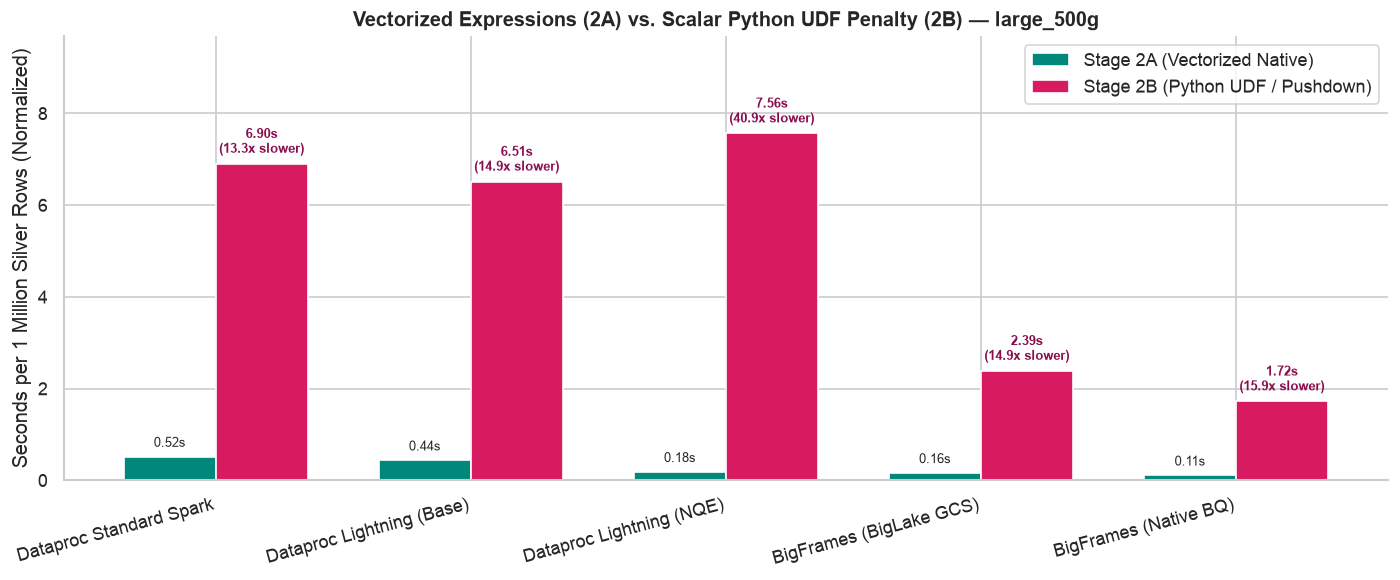

In [9]:
# ==============================================================================
# 8. STAGE 2A VECTORIZED VS. STAGE 2B PYTHON UDF NORMALIZED ANALYSIS
# ==============================================================================
if {"stage2a_silver_vectorized", "stage2b_silver_udf"}.issubset(set(present_stages)):
    s2_rows = []
    for eng in present_engines:
        sub2a = df[(df["engine_variant"] == eng) & (df["stage_id"] == "stage2a_silver_vectorized")]
        sub2b = df[(df["engine_variant"] == eng) & (df["stage_id"] == "stage2b_silver_udf")]
        if sub2a.empty or sub2b.empty:
            continue
        r2a = sub2a.iloc[0]
        r2b = sub2b.iloc[0]

        sf_2a = float(r2a["sample_fraction"])
        sf_2b = float(r2b["sample_fraction"])
        norm_2a_sec = float(r2a["wall_clock_sec"]) / sf_2a
        norm_2b_sec = float(r2b["wall_clock_sec"]) / sf_2b
        slowdown_factor = norm_2b_sec / norm_2a_sec

        sec_per_1m_2a = float(r2a["wall_clock_sec"]) / (float(r2a["output_row_count"]) / 1e6)
        sec_per_1m_2b = float(r2b["wall_clock_sec"]) / (float(r2b["output_row_count"]) / 1e6)

        s2_rows.append({
            "engine_variant": eng,
            "2a_wall_sec": float(r2a["wall_clock_sec"]),
            "2b_wall_sec": float(r2b["wall_clock_sec"]),
            "2b_sample_fraction": sf_2b,
            "2b_full_scale_equiv_sec": norm_2b_sec,
            "2a_sec_per_1m_rows": sec_per_1m_2a,
            "2b_sec_per_1m_rows": sec_per_1m_2b,
            "udf_slowdown_factor": slowdown_factor,
            "nqe_fallback_note": str(r2b.get("nqe_fallback_note", "") or ""),
        })

    udf_df = pd.DataFrame(s2_rows)
    show_table(
        udf_df.set_index("engine_variant").rename(index=ENGINE_LABELS),
        {
            "2a_wall_sec": "{:.2f} s",
            "2b_wall_sec": "{:.2f} s",
            "2b_sample_fraction": "{:.2%}",
            "2b_full_scale_equiv_sec": "{:,.2f} s",
            "2a_sec_per_1m_rows": "{:.2f} s/M",
            "2b_sec_per_1m_rows": "{:.2f} s/M",
            "udf_slowdown_factor": "{:.2f}x",
        },
    )

    notes = udf_df[udf_df["nqe_fallback_note"].str.len() > 0]
    if not notes.empty:
        print("\nCaptured NQE Physical Plan Fallback Telemetry:")
        for _, nrow in notes.iterrows():
            print(f"  [{nrow['engine_variant']}] {nrow['nqe_fallback_note']}")

    fig, ax = plt.subplots(figsize=(12, 5))
    x = np.arange(len(udf_df))
    bw = 0.36
    ax.bar(x - bw / 2, udf_df["2a_sec_per_1m_rows"], width=bw, color="#00897B", label="Stage 2A (Vectorized Native)")
    ax.bar(x + bw / 2, udf_df["2b_sec_per_1m_rows"], width=bw, color="#D81B60", label="Stage 2B (Python UDF / Pushdown)")

    max_y = max(udf_df["2a_sec_per_1m_rows"].max(), udf_df["2b_sec_per_1m_rows"].max())
    for idx, row in udf_df.iterrows():
        ax.text(idx - bw / 2, row["2a_sec_per_1m_rows"] + max_y * 0.02, f"{row['2a_sec_per_1m_rows']:.2f}s", ha="center", va="bottom", fontsize=8)
        ratio_lbl = f"{row['udf_slowdown_factor']:.1f}x slower" if row["udf_slowdown_factor"] >= 1.0 else f"{1.0/row['udf_slowdown_factor']:.1f}x faster"
        ax.text(
            idx + bw / 2,
            row["2b_sec_per_1m_rows"] + max_y * 0.02,
            f"{row['2b_sec_per_1m_rows']:.2f}s\n({ratio_lbl})",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
            color="#880E4F",
        )

    ax.set_xticks(x)
    ax.set_xticklabels([ENGINE_LABELS[e] for e in udf_df["engine_variant"]], rotation=15, ha="right")
    ax.set_ylabel("Seconds per 1 Million Silver Rows (Normalized)")
    ax.set_title(f"Vectorized Expressions (2A) vs. Scalar Python UDF Penalty (2B) — {PRIMARY_DEEP_DIVE_SCALE}")
    ax.set_ylim(0, max_y * 1.28)
    ax.legend(frameon=True, loc="upper right")
    plt.tight_layout()
    plt.show()
else:
    udf_df = pd.DataFrame()
    print("Stage 2B telemetry not present in this run (RUN_PYTHON_UDF_STAGE=false).")


## 9. Single-Scale Deep-Dive: Lightning Surcharge Break-Even & Parameterized Cross-Platform TCO Matrix

Evaluates **Dataproc cluster commitments & Spot EFM blends** against **BigQuery Enterprise Edition** on `PRIMARY_DEEP_DIVE_SCALE` with exact hardware accounting (`worker_local_ssds` inferred per machine tier: `2` SSDs for `2 x n2d-standard-8`, `8` SSDs for `4 x n2d-standard-16`) plus clear separation of **Dedicated `baseline = max` reservation ceilings** (`0s` autoscale cold-start, unshared wall-clock billing) vs. **Shared Enterprise slot-hour consumption** (`0s` idle waste).


Lightning Surcharge Break-Even Analysis (large_500g) — Scope: Full Cluster (Master + Workers) (68 vCPUs, 8 x 375GB NVMe Local SSDs)


,std_cluster_usd_hr,lgt_cluster_usd_hr,surcharge_usd_hr,req_breakeven_speedup_pct,req_runtime_reduction_pct,measured_base_speedup_pct,base_net_cost_delta_pct,measured_nqe_speedup_pct,nqe_net_cost_delta_pct,nqe_verdict
cluster_blend,,,,,,,,,,
100% On-Demand,$4.2437/hr,$4.4137/hr,+$0.1700/hr,+4.01%,-3.85%,+17.0%,-11.1%,+139.6%,-56.6%,NET SAVINGS
15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),$2.2090/hr,$2.3790/hr,+$0.1700/hr,+7.70%,-7.15%,+17.0%,-8.0%,+139.6%,-55.0%,NET SAVINGS
100% 1-Yr CUD,$2.9252/hr,$3.0952/hr,+$0.1700/hr,+5.81%,-5.49%,+17.0%,-9.6%,+139.6%,-55.8%,NET SAVINGS
100% 3-Yr CUD,$2.2838/hr,$2.4538/hr,+$0.1700/hr,+7.44%,-6.93%,+17.0%,-8.2%,+139.6%,-55.2%,NET SAVINGS


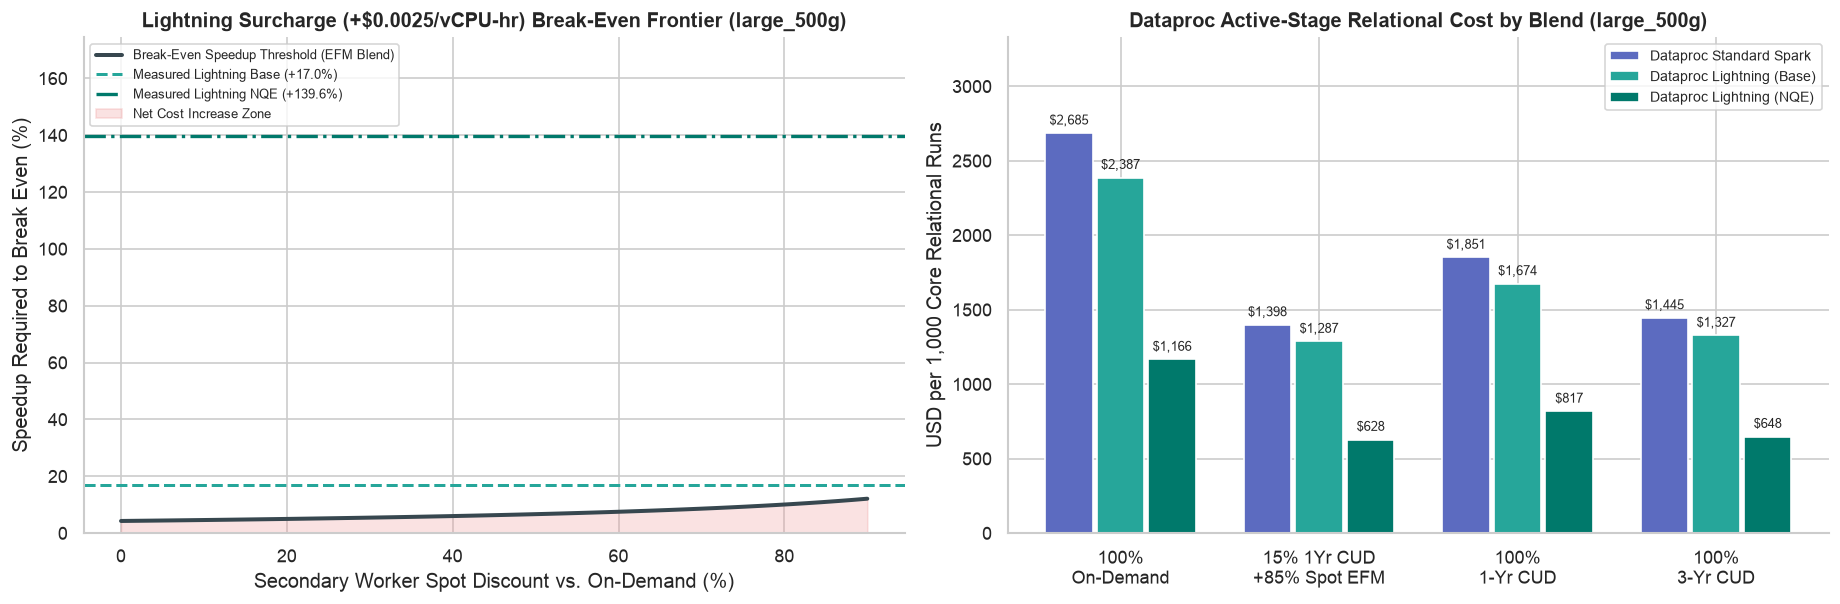

In [10]:
# ==============================================================================
# 9A. LIGHTNING SURCHARGE (+$0.0025/vCPU-hr) BREAK-EVEN ANALYSIS
# ==============================================================================
breakeven_rows = []
std_rel_sec = float(df.loc[(df["engine_variant"] == "spark_standard") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum()) if "spark_standard" in present_engines else np.nan
lgt_base_rel_sec = float(df.loc[(df["engine_variant"] == "spark_lightning_base") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum()) if "spark_lightning_base" in present_engines else np.nan
lgt_nqe_rel_sec = float(df.loc[(df["engine_variant"] == "spark_lightning_nqe") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum()) if "spark_lightning_nqe" in present_engines else np.nan

for blend_name in BLEND_WEIGHTS:
    r_std = compute_dataproc_hourly_cost(blend_name, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=False, include_master=INCLUDE_MASTER_IN_TCO)
    r_lgt = compute_dataproc_hourly_cost(blend_name, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=True, include_master=INCLUDE_MASTER_IN_TCO)
    req_speedup_pct = ((r_lgt["total_cluster_hr"] / r_std["total_cluster_hr"]) - 1.0) * 100.0
    req_runtime_red_pct = (1.0 - (r_std["total_cluster_hr"] / r_lgt["total_cluster_hr"])) * 100.0

    nqe_speedup_pct = ((std_rel_sec / lgt_nqe_rel_sec) - 1.0) * 100.0 if np.isfinite(std_rel_sec) and np.isfinite(lgt_nqe_rel_sec) else np.nan
    base_speedup_pct = ((std_rel_sec / lgt_base_rel_sec) - 1.0) * 100.0 if np.isfinite(std_rel_sec) and np.isfinite(lgt_base_rel_sec) else np.nan

    nqe_cost_delta_pct = (((r_lgt["total_cluster_hr"] * lgt_nqe_rel_sec) / (r_std["total_cluster_hr"] * std_rel_sec)) - 1.0) * 100.0 if np.isfinite(nqe_speedup_pct) else np.nan
    base_cost_delta_pct = (((r_lgt["total_cluster_hr"] * lgt_base_rel_sec) / (r_std["total_cluster_hr"] * std_rel_sec)) - 1.0) * 100.0 if np.isfinite(base_speedup_pct) else np.nan

    if np.isfinite(nqe_cost_delta_pct):
        nqe_verdict = "NET SAVINGS" if nqe_cost_delta_pct < 0 else "SURCHARGE EXCEEDS SPEEDUP"
    else:
        nqe_verdict = "N/A"

    breakeven_rows.append({
        "cluster_blend": blend_name,
        "std_cluster_usd_hr": r_std["total_cluster_hr"],
        "lgt_cluster_usd_hr": r_lgt["total_cluster_hr"],
        "surcharge_usd_hr": r_lgt["lightning_surcharge_hr"],
        "req_breakeven_speedup_pct": req_speedup_pct,
        "req_runtime_reduction_pct": req_runtime_red_pct,
        "measured_base_speedup_pct": base_speedup_pct,
        "base_net_cost_delta_pct": base_cost_delta_pct,
        "measured_nqe_speedup_pct": nqe_speedup_pct,
        "nqe_net_cost_delta_pct": nqe_cost_delta_pct,
        "nqe_verdict": nqe_verdict,
    })

breakeven_df = pd.DataFrame(breakeven_rows)
scope_note = "Full Cluster (Master + Workers)" if INCLUDE_MASTER_IN_TCO else "Workers Only"
billed_vcpu_cnt = int(CLUSTER_TOPOLOGY["master_vcpus"] + CLUSTER_TOPOLOGY["worker_vcpus"] if INCLUDE_MASTER_IN_TCO else CLUSTER_TOPOLOGY["worker_vcpus"])
print(
    f"Lightning Surcharge Break-Even Analysis ({PRIMARY_DEEP_DIVE_SCALE}) — Scope: {scope_note} "
    f"({billed_vcpu_cnt} vCPUs, {CLUSTER_TOPOLOGY['worker_local_ssds']} x 375GB NVMe Local SSDs)"
)
show_table(
    breakeven_df.set_index("cluster_blend"),
    {
        "std_cluster_usd_hr": "${:.4f}/hr",
        "lgt_cluster_usd_hr": "${:.4f}/hr",
        "surcharge_usd_hr": "+${:.4f}/hr",
        "req_breakeven_speedup_pct": "+{:.2f}%",
        "req_runtime_reduction_pct": "-{:.2f}%",
        "measured_base_speedup_pct": "{:+.1f}%",
        "base_net_cost_delta_pct": "{:+.1f}%",
        "measured_nqe_speedup_pct": "{:+.1f}%",
        "nqe_net_cost_delta_pct": "{:+.1f}%",
    },
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.2))

spot_discounts = np.linspace(0.0, 0.90, 50)
req_speedup_curve = []
for disc in spot_discounts:
    gce_od = PRICING_CONFIG["gce_n2d_standard"]["on_demand"]
    gce_1yr = PRICING_CONFIG["gce_n2d_standard"]["cud_1yr"]
    m_v = CLUSTER_TOPOLOGY["master_vcpus"] if INCLUDE_MASTER_IN_TCO else 0
    m_r = CLUSTER_TOPOLOGY["master_ram_gb"] if INCLUDE_MASTER_IN_TCO else 0
    w_v = CLUSTER_TOPOLOGY["worker_vcpus"]
    w_r = CLUSTER_TOPOLOGY["worker_ram_gb"]
    w_s = CLUSTER_TOPOLOGY["worker_local_ssds"]
    std_hr = (
        (m_v * gce_1yr["vcpu_hr"] + m_r * gce_1yr["ram_gb_hr"])
        + 0.15 * (w_v * gce_1yr["vcpu_hr"] + w_r * gce_1yr["ram_gb_hr"] + w_s * PRICING_CONFIG["local_ssd_375gb_hr"]["cud_1yr"])
        + 0.85 * ((1.0 - disc) * (w_v * gce_od["vcpu_hr"] + w_r * gce_od["ram_gb_hr"] + w_s * PRICING_CONFIG["local_ssd_375gb_hr"]["on_demand"]))
        + (m_v + w_v) * PRICING_CONFIG["dataproc_mgmt_fee_per_vcpu_hr"]
    )
    lgt_hr = std_hr + (m_v + w_v) * PRICING_CONFIG["lightning_surcharge_per_vcpu_hr"]
    req_speedup_curve.append(((lgt_hr / std_hr) - 1.0) * 100.0)

ax1.plot(spot_discounts * 100.0, req_speedup_curve, color="#37474F", linewidth=2.4, label="Break-Even Speedup Threshold (EFM Blend)")
max_y_be = max(req_speedup_curve)
if np.isfinite(breakeven_df["measured_base_speedup_pct"].iloc[0]):
    base_sp = float(breakeven_df["measured_base_speedup_pct"].iloc[0])
    max_y_be = max(max_y_be, base_sp)
    ax1.axhline(base_sp, color="#26A69A", linestyle="--", linewidth=1.8, label=f"Measured Lightning Base ({base_sp:+.1f}%)")
if np.isfinite(breakeven_df["measured_nqe_speedup_pct"].iloc[0]):
    nqe_sp = float(breakeven_df["measured_nqe_speedup_pct"].iloc[0])
    max_y_be = max(max_y_be, nqe_sp)
    ax1.axhline(nqe_sp, color="#00796B", linestyle="-.", linewidth=2.0, label=f"Measured Lightning NQE ({nqe_sp:+.1f}%)")
ax1.fill_between(spot_discounts * 100.0, 0, req_speedup_curve, color="#EF9A9A", alpha=0.28, label="Net Cost Increase Zone")
ax1.set_xlabel("Secondary Worker Spot Discount vs. On-Demand (%)")
ax1.set_ylabel("Speedup Required to Break Even (%)")
ax1.set_title(f"Lightning Surcharge (+$0.0025/vCPU-hr) Break-Even Frontier ({PRIMARY_DEEP_DIVE_SCALE})")
ax1.set_ylim(0, max(20.0, max_y_be * 1.25))
ax1.legend(fontsize=8, loc="upper left", frameon=True)

spark_order_present = [e for e in ["spark_standard", "spark_lightning_base", "spark_lightning_nqe"] if e in present_engines]
x_b = np.arange(len(BLEND_WEIGHTS))
bw = 0.78 / max(1, len(spark_order_present))
max_blend_cost = 0.0
all_bar_series = []
for i, eng in enumerate(spark_order_present):
    is_lgt = eng != "spark_standard"
    sec = float(df.loc[(df["engine_variant"] == eng) & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "wall_clock_sec"].sum())
    costs_1k = [
        compute_dataproc_hourly_cost(b, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=is_lgt, include_master=INCLUDE_MASTER_IN_TCO)["total_cluster_hr"]
        * (sec / 3600.0)
        * 1000.0
        for b in BLEND_WEIGHTS
    ]
    max_blend_cost = max(max_blend_cost, max(costs_1k))
    all_bar_series.append((i, eng, costs_1k))

for i, eng, costs_1k in all_bar_series:
    offset = (i - (len(spark_order_present) - 1) / 2.0) * bw
    bars = ax2.bar(x_b + offset, costs_1k, width=bw * 0.92, label=ENGINE_LABELS[eng], color=ENGINE_PALETTE[eng])
    for bar, v in zip(bars, costs_1k):
        ax2.text(bar.get_x() + bar.get_width() / 2.0, v + max_blend_cost * 0.015, f"${v:,.0f}" if v >= 100 else f"${v:.2f}", ha="center", va="bottom", fontsize=7.5)

ax2.set_xticks(x_b)
ax2.set_xticklabels(["100%\nOn-Demand", "15% 1Yr CUD\n+85% Spot EFM", "100%\n1-Yr CUD", "100%\n3-Yr CUD"])
ax2.set_ylabel("USD per 1,000 Core Relational Runs")
ax2.set_title(f"Dataproc Active-Stage Relational Cost by Blend ({PRIMARY_DEEP_DIVE_SCALE})")
ax2.set_ylim(0, max(1.0, max_blend_cost) * 1.24)
ax2.legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()


--- Full Parameterized TCO Matrix (large_500g: Per Run & 1,000 Runs) ---
Reservation Accounting Note: At 200 slots, a fixed baseline=max dedicated reservation eliminates autoscale cold-start (0s warmup). Unshared single-pipeline runs bill full reservation wall-clock hours [Lens (b)]; shared enterprise reservations bill only consumed slot-hours [Lens (a)].


,engine_label,pricing_tier,billing_lens,hourly_rate_usd,rel_cost_per_run_usd,full_cost_per_run_usd,rel_cost_1k_runs_usd,full_cost_1k_runs_usd
0,Dataproc Standard Spark,100% On-Demand,Active Stage Time (100% Busy Shared Cluster),$4.2437/hr,$2.68530,$2.97587,"$2,685.30","$2,975.87"
1,Dataproc Standard Spark,100% On-Demand,Cluster-Lifetime (70% Util / Driver Gap),$4.2437/hr,$3.83614,$4.25124,"$3,836.14","$4,251.24"
2,Dataproc Standard Spark,100% On-Demand,Ephemeral Cluster (+120s Spin-Up/Down),$4.2437/hr,$2.82675,$3.11732,"$2,826.75","$3,117.32"
3,Dataproc Standard Spark,15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),Active Stage Time (100% Busy Shared Cluster),$2.2090/hr,$1.39780,$1.54906,"$1,397.80","$1,549.06"
4,Dataproc Standard Spark,15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),Cluster-Lifetime (70% Util / Driver Gap),$2.2090/hr,$1.99686,$2.21294,"$1,996.86","$2,212.94"
5,Dataproc Standard Spark,15% Primary (1-Yr CUD) + 85% Spot Secondary (EFM),Ephemeral Cluster (+120s Spin-Up/Down),$2.2090/hr,$1.47143,$1.62269,"$1,471.43","$1,622.69"
6,Dataproc Standard Spark,100% 1-Yr CUD,Active Stage Time (100% Busy Shared Cluster),$2.9252/hr,$1.85101,$2.05131,"$1,851.01","$2,051.31"
7,Dataproc Standard Spark,100% 3-Yr CUD,Active Stage Time (100% Busy Shared Cluster),$2.2838/hr,$1.44511,$1.60148,"$1,445.11","$1,601.48"
8,Dataproc Standard Spark,"Worker-Only List Parity (64 vCPUs, 8 SSDs)",Matches telemetry est_list_cost_usd,$4.0134/hr,$2.53957,$2.81438,"$2,539.57","$2,814.38"
9,Dataproc Lightning (Base),100% On-Demand,Active Stage Time (100% Busy Shared Cluster),$4.4137/hr,$2.38693,$2.67211,"$2,386.93","$2,672.11"


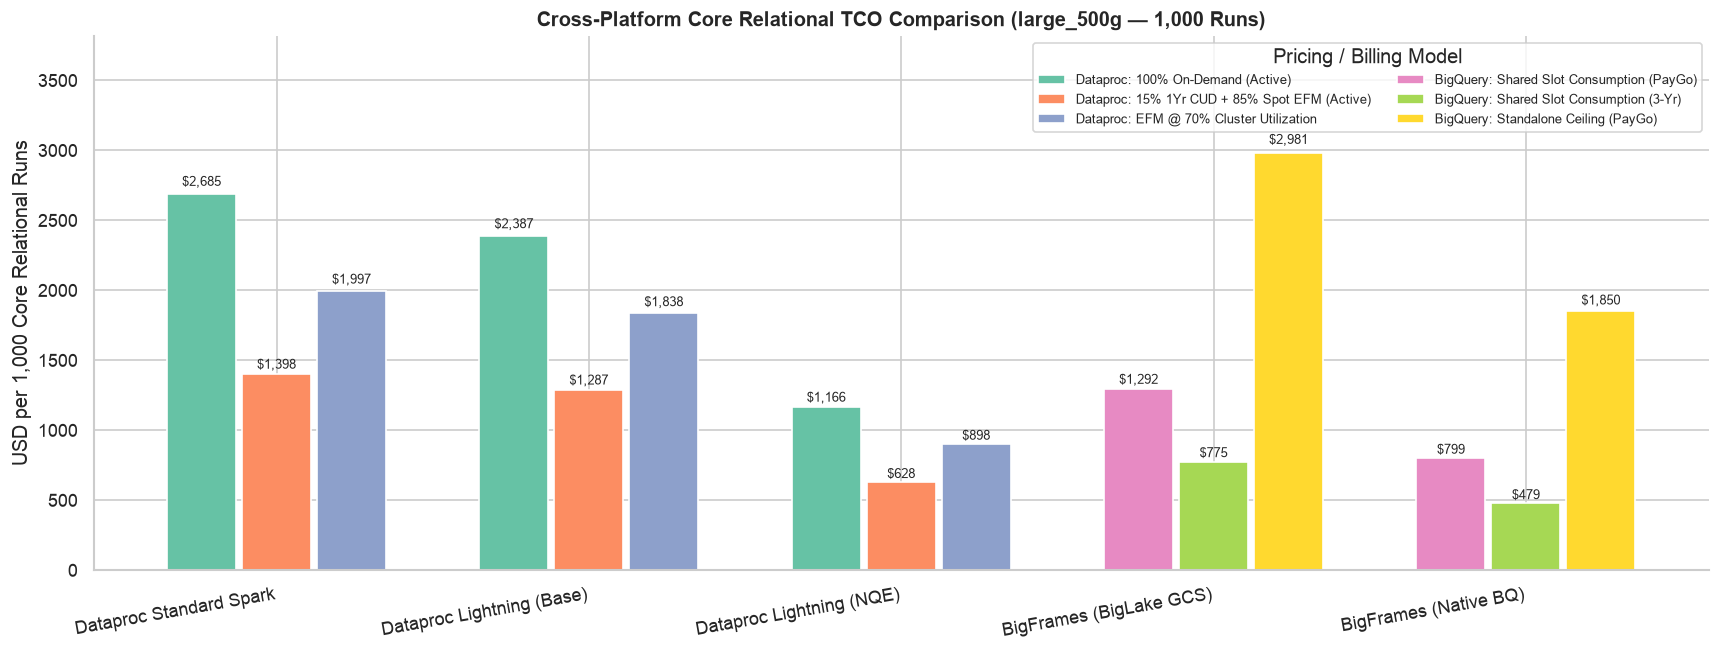


--- Storage Reference Rates (US Multi-Region) ---


,storage_tier,unit_rate,1_tb_monthly_usd,100_tb_monthly_usd,notes
0,"GCS Standard (Open Parquet, US Multi-Region)",$0.026 / GB-month,$26.00 / mo,"$2,600.00 / mo",Zero intra-US egress to us-central1 Dataproc GCE; shared by Spark & BigLake
1,"BigQuery Active Physical Storage (Capacitor, US)",$0.040 / GiB-month,$40.96 / mo,"$4,096.00 / mo",Includes time-travel/fail-safe physical bytes; Capacitor compression reduces bytes scanned
2,"BigQuery Long-Term Physical Storage (90d+ Unchanged, US)",$0.020 / GiB-month,$20.48 / mo,"$2,048.00 / mo",Automatic 50% physical storage discount after 90 days without table mutation


In [11]:
# ==============================================================================
# 9B. PARAMETERIZED TCO MATRIX (DATAPROC BLENDS + CLUSTER LIFETIME + DUAL BQ LENSES)
# ==============================================================================
tco_rows = []
for eng in present_engines:
    eng_df = df[df["engine_variant"] == eng].copy()
    rel_df = eng_df[eng_df["stage_id"].isin(CORE_RELATIONAL_STAGES)]
    rel_sec = float(rel_df["wall_clock_sec"].sum())
    full_sec = float(eng_df["wall_clock_sec"].sum())

    if eng.startswith("spark_"):
        is_lgt = eng != "spark_standard"
        for blend_name in BLEND_WEIGHTS:
            rate = compute_dataproc_hourly_cost(
                blend_name, CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=is_lgt, include_master=INCLUDE_MASTER_IN_TCO
            )
            rel_cost = rate["total_cluster_hr"] * (rel_sec / 3600.0)
            full_cost = rate["total_cluster_hr"] * (full_sec / 3600.0)
            tco_rows.append({
                "engine_variant": eng,
                "engine_label": ENGINE_LABELS[eng],
                "pricing_tier": blend_name,
                "billing_lens": "Active Stage Time (100% Busy Shared Cluster)",
                "hourly_rate_usd": rate["total_cluster_hr"],
                "rel_cost_per_run_usd": rel_cost,
                "full_cost_per_run_usd": full_cost,
                "rel_cost_1k_runs_usd": rel_cost * 1000.0,
                "full_cost_1k_runs_usd": full_cost * 1000.0,
            })

            if blend_name in ("100% On-Demand", ACTIVE_CLUSTER_BLEND):
                rel_util_cost = rel_cost / SPARK_CLUSTER_UTILIZATION_SENSITIVITY
                full_util_cost = full_cost / SPARK_CLUSTER_UTILIZATION_SENSITIVITY
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": blend_name,
                    "billing_lens": f"Cluster-Lifetime ({int(SPARK_CLUSTER_UTILIZATION_SENSITIVITY*100)}% Util / Driver Gap)",
                    "hourly_rate_usd": rate["total_cluster_hr"],
                    "rel_cost_per_run_usd": rel_util_cost,
                    "full_cost_per_run_usd": full_util_cost,
                    "rel_cost_1k_runs_usd": rel_util_cost * 1000.0,
                    "full_cost_1k_runs_usd": full_util_cost * 1000.0,
                })

                rel_eph_cost = rate["total_cluster_hr"] * ((rel_sec + SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC) / 3600.0)
                full_eph_cost = rate["total_cluster_hr"] * ((full_sec + SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC) / 3600.0)
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": blend_name,
                    "billing_lens": f"Ephemeral Cluster (+{int(SPARK_EPHEMERAL_PROVISION_OVERHEAD_SEC)}s Spin-Up/Down)",
                    "hourly_rate_usd": rate["total_cluster_hr"],
                    "rel_cost_per_run_usd": rel_eph_cost,
                    "full_cost_per_run_usd": full_eph_cost,
                    "rel_cost_1k_runs_usd": rel_eph_cost * 1000.0,
                    "full_cost_1k_runs_usd": full_eph_cost * 1000.0,
                })

        w_rate_od = compute_dataproc_hourly_cost(
            "100% On-Demand", CLUSTER_TOPOLOGY, PRICING_CONFIG, lightning=is_lgt, include_master=False
        )
        tco_rows.append({
            "engine_variant": eng,
            "engine_label": ENGINE_LABELS[eng],
            "pricing_tier": f"Worker-Only List Parity ({CLUSTER_TOPOLOGY['worker_vcpus']} vCPUs, {CLUSTER_TOPOLOGY['worker_local_ssds']} SSDs)",
            "billing_lens": "Matches telemetry est_list_cost_usd",
            "hourly_rate_usd": w_rate_od["total_cluster_hr"],
            "rel_cost_per_run_usd": float(rel_df["est_list_cost_usd"].sum()),
            "full_cost_per_run_usd": float(eng_df["est_list_cost_usd"].sum()),
            "rel_cost_1k_runs_usd": float(rel_df["est_list_cost_usd"].sum()) * 1000.0,
            "full_cost_1k_runs_usd": float(eng_df["est_list_cost_usd"].sum()) * 1000.0,
        })
    else:
        raw_cap = eng_df["bq_slot_cap"].dropna()
        slot_cap = int(raw_cap.iloc[0]) if not raw_cap.empty else None
        rel_slot_hrs = float(rel_df["bq_slot_seconds"].sum()) / 3600.0
        full_slot_hrs = float(eng_df["bq_slot_seconds"].sum()) / 3600.0

        min_sec = PRICING_CONFIG["bq_autoscale_min_bill_sec"]
        slot_inc = int(PRICING_CONFIG["bq_autoscale_increment_slots"])
        rel_pass_floored_sec = max(min_sec, rel_sec)
        full_pass_floored_sec = max(min_sec, full_sec)

        rel_avg_slots = float((rel_df["bq_slot_seconds"].sum() / rel_sec)) if rel_sec > 0 else 0.0
        full_avg_slots = float((eng_df["bq_slot_seconds"].sum() / full_sec)) if full_sec > 0 else 0.0
        rel_stepped_slots = min(slot_cap, max(slot_inc, int(math.ceil(rel_avg_slots / slot_inc) * slot_inc))) if slot_cap else None
        full_stepped_slots = min(slot_cap, max(slot_inc, int(math.ceil(full_avg_slots / slot_inc) * slot_inc))) if slot_cap else None

        for tier_name, slot_rate in PRICING_CONFIG["bq_enterprise_slot_hr"].items():
            # Lens (a): Shared Reservation Slot-Hour Consumption (0s idle waste)
            rel_shared = rel_slot_hrs * slot_rate
            full_shared = full_slot_hrs * slot_rate
            tco_rows.append({
                "engine_variant": eng,
                "engine_label": ENGINE_LABELS[eng],
                "pricing_tier": tier_name,
                "billing_lens": "(a) Shared Slot-Hr Consumption (0s idle waste)",
                "hourly_rate_usd": (slot_cap * slot_rate) if slot_cap else np.nan,
                "rel_cost_per_run_usd": rel_shared,
                "full_cost_per_run_usd": full_shared,
                "rel_cost_1k_runs_usd": rel_shared * 1000.0,
                "full_cost_1k_runs_usd": full_shared * 1000.0,
            })

            if slot_cap is not None:
                # Lens (b): Standalone Unshared Reservation Ceiling (Actual Contiguous Wall-Clock)
                rel_ceil = slot_cap * (rel_sec / 3600.0) * slot_rate
                full_ceil = slot_cap * (full_sec / 3600.0) * slot_rate
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": tier_name,
                    "billing_lens": f"(b) Standalone {slot_cap}-Slot Ceiling (Wall-Clock)",
                    "hourly_rate_usd": slot_cap * slot_rate,
                    "rel_cost_per_run_usd": rel_ceil,
                    "full_cost_per_run_usd": full_ceil,
                    "rel_cost_1k_runs_usd": rel_ceil * 1000.0,
                    "full_cost_1k_runs_usd": full_ceil * 1000.0,
                })

                # Lens (b*): Contiguous-Pass Autoscale 60s Min-Bill Floor
                rel_floor_ceil = slot_cap * (rel_pass_floored_sec / 3600.0) * slot_rate
                full_floor_ceil = slot_cap * (full_pass_floored_sec / 3600.0) * slot_rate
                tco_rows.append({
                    "engine_variant": eng,
                    "engine_label": ENGINE_LABELS[eng],
                    "pricing_tier": tier_name,
                    "billing_lens": f"(b*) Contiguous Pass 60s Min-Bill Floor ({slot_cap} slots)",
                    "hourly_rate_usd": slot_cap * slot_rate,
                    "rel_cost_per_run_usd": rel_floor_ceil,
                    "full_cost_per_run_usd": full_floor_ceil,
                    "rel_cost_1k_runs_usd": rel_floor_ceil * 1000.0,
                    "full_cost_1k_runs_usd": full_floor_ceil * 1000.0,
                })

                # Lens (b-step): Contiguous-Pass Autoscale 60s Floor @ 50-slot increment
                if rel_stepped_slots and full_stepped_slots:
                    rel_step_cost = rel_stepped_slots * (rel_pass_floored_sec / 3600.0) * slot_rate
                    full_step_cost = full_stepped_slots * (full_pass_floored_sec / 3600.0) * slot_rate
                    tco_rows.append({
                        "engine_variant": eng,
                        "engine_label": ENGINE_LABELS[eng],
                        "pricing_tier": tier_name,
                        "billing_lens": f"(b-step) Autoscale {slot_inc}-Slot Increment + 60s Floor ({rel_stepped_slots}/{full_stepped_slots} slots)",
                        "hourly_rate_usd": rel_stepped_slots * slot_rate,
                        "rel_cost_per_run_usd": rel_step_cost,
                        "full_cost_per_run_usd": full_step_cost,
                        "rel_cost_1k_runs_usd": rel_step_cost * 1000.0,
                        "full_cost_1k_runs_usd": full_step_cost * 1000.0,
                    })

tco_df = pd.DataFrame(tco_rows)
print(f"--- Full Parameterized TCO Matrix ({PRIMARY_DEEP_DIVE_SCALE}: Per Run & 1,000 Runs) ---")
print(
    f"Reservation Accounting Note: At {CLUSTER_TOPOLOGY['bq_slot_cap']} slots, a fixed baseline=max dedicated reservation eliminates "
    "autoscale cold-start (0s warmup). Unshared single-pipeline runs bill full reservation wall-clock hours [Lens (b)]; "
    "shared enterprise reservations bill only consumed slot-hours [Lens (a)]."
)
show_table(
    tco_df.drop(columns=["engine_variant"]),
    {
        "hourly_rate_usd": "${:.4f}/hr",
        "rel_cost_per_run_usd": "${:.5f}",
        "full_cost_per_run_usd": "${:.5f}",
        "rel_cost_1k_runs_usd": "${:,.2f}",
        "full_cost_1k_runs_usd": "${:,.2f}",
    },
)

spark_tiers = [
    ("100% On-Demand", "Active Stage Time (100% Busy Shared Cluster)", "Dataproc: 100% On-Demand (Active)", "#66C2A5"),
    (ACTIVE_CLUSTER_BLEND, "Active Stage Time (100% Busy Shared Cluster)", "Dataproc: 15% 1Yr CUD + 85% Spot EFM (Active)", "#FC8D62"),
    (ACTIVE_CLUSTER_BLEND, f"Cluster-Lifetime ({int(SPARK_CLUSTER_UTILIZATION_SENSITIVITY*100)}% Util / Driver Gap)", "Dataproc: EFM @ 70% Cluster Utilization", "#8DA0CB"),
]
bq_paygo_key = next(iter(PRICING_CONFIG["bq_enterprise_slot_hr"]))
bq_3yr_key = list(PRICING_CONFIG["bq_enterprise_slot_hr"])[-1]
bq_tiers = [
    (bq_paygo_key, "(a) Shared Slot-Hr Consumption (0s idle waste)", "BigQuery: Shared Slot Consumption (PayGo)", "#E78AC3"),
    (bq_3yr_key, "(a) Shared Slot-Hr Consumption (0s idle waste)", "BigQuery: Shared Slot Consumption (3-Yr)", "#A6D854"),
    (bq_paygo_key, f"(b) Standalone {CLUSTER_TOPOLOGY['bq_slot_cap']}-Slot Ceiling (Wall-Clock)", "BigQuery: Standalone Ceiling (PayGo)", "#FFD92F"),
]

fig, ax = plt.subplots(figsize=(14.5, 5.6))
x_pos = np.arange(len(present_engines))
bw = 0.24
plotted_labels = set()
max_hl_cost = 0.0

for e_idx, eng in enumerate(present_engines):
    if eng.startswith("spark_"):
        bars_spec = []
        for tier_key, lens_key, legend_lbl, color in spark_tiers:
            match = tco_df[
                (tco_df["engine_variant"] == eng)
                & (tco_df["pricing_tier"] == tier_key)
                & (tco_df["billing_lens"] == lens_key)
            ]
            if not match.empty:
                bars_spec.append((float(match.iloc[0]["rel_cost_1k_runs_usd"]), legend_lbl, color))
    else:
        bars_spec = []
        for tier_key, lens_key, legend_lbl, color in bq_tiers:
            match = tco_df[
                (tco_df["engine_variant"] == eng)
                & (tco_df["pricing_tier"] == tier_key)
                & (tco_df["billing_lens"] == lens_key)
            ]
            if not match.empty:
                bars_spec.append((float(match.iloc[0]["rel_cost_1k_runs_usd"]), legend_lbl, color))

    n_bars = len(bars_spec)
    for b_idx, (val, legend_lbl, color) in enumerate(bars_spec):
        max_hl_cost = max(max_hl_cost, val)
        offset = (b_idx - (n_bars - 1) / 2.0) * bw
        lbl = legend_lbl if legend_lbl not in plotted_labels else None
        plotted_labels.add(legend_lbl)
        bar = ax.bar(x_pos[e_idx] + offset, val, width=bw * 0.92, color=color, edgecolor="white", label=lbl)
        ax.text(
            bar[0].get_x() + bar[0].get_width() / 2.0,
            val + max(0.5, val * 0.015),
            f"${val:,.0f}" if val >= 100 else f"${val:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_xticks(x_pos)
ax.set_xticklabels([ENGINE_LABELS[e] for e in present_engines], rotation=10, ha="right")
ax.set_ylabel("USD per 1,000 Core Relational Runs")
ax.set_title(f"Cross-Platform Core Relational TCO Comparison ({PRIMARY_DEEP_DIVE_SCALE} — 1,000 Runs)")
ax.set_ylim(0, max(1.0, max_hl_cost) * 1.28)
ax.legend(title="Pricing / Billing Model", fontsize=8, ncol=2, loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

storage_ref_df = pd.DataFrame([
    {
        "storage_tier": "GCS Standard (Open Parquet, US Multi-Region)",
        "unit_rate": f"${PRICING_CONFIG['storage_monthly_usd']['gcs_standard_per_gb']:.3f} / GB-month",
        "1_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["gcs_standard_per_gb"] * 1000.0,
        "100_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["gcs_standard_per_gb"] * 100_000.0,
        "notes": "Zero intra-US egress to us-central1 Dataproc GCE; shared by Spark & BigLake",
    },
    {
        "storage_tier": "BigQuery Active Physical Storage (Capacitor, US)",
        "unit_rate": f"${PRICING_CONFIG['storage_monthly_usd']['bq_active_physical_per_gib']:.3f} / GiB-month",
        "1_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_active_physical_per_gib"] * 1024.0,
        "100_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_active_physical_per_gib"] * 1024.0 * 100.0,
        "notes": "Includes time-travel/fail-safe physical bytes; Capacitor compression reduces bytes scanned",
    },
    {
        "storage_tier": "BigQuery Long-Term Physical Storage (90d+ Unchanged, US)",
        "unit_rate": f"${PRICING_CONFIG['storage_monthly_usd']['bq_long_term_physical_per_gib']:.3f} / GiB-month",
        "1_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_long_term_physical_per_gib"] * 1024.0,
        "100_tb_monthly_usd": PRICING_CONFIG["storage_monthly_usd"]["bq_long_term_physical_per_gib"] * 1024.0 * 100.0,
        "notes": "Automatic 50% physical storage discount after 90 days without table mutation",
    },
])
print("\n--- Storage Reference Rates (US Multi-Region) ---")
show_table(
    storage_ref_df,
    {
        "1_tb_monthly_usd": "${:,.2f} / mo",
        "100_tb_monthly_usd": "${:,.2f} / mo",
    },
)


In [12]:
# ==============================================================================
# 10. CONDITIONAL DYNAMIC EXECUTIVE SUMMARY & MULTI-SCALE GUIDANCE
# ==============================================================================
rel_totals = df[df["stage_id"].isin(CORE_RELATIONAL_STAGES)].groupby("engine_variant")["wall_clock_sec"].sum()
fastest_rel_eng = rel_totals.idxmin()
fastest_rel_sec = float(rel_totals.min())

print(f"EXECUTIVE BENCHMARK SUMMARY ({PROVENANCE} | Deep-Dive={PRIMARY_DEEP_DIVE_SCALE} | Scales={len(available_scales)})")
print("-" * 92)

if parity_overall_pass:
    print(
        f"1. Correctness Parity    : PASS across all {len(parity_df)}/{len(parity_df)} checks "
        f"({len(available_scales)} scale(s), 0 row/sample drift, <= {PARITY_TOLERANCE_PCT}% checksum tol)."
    )
else:
    print(f"1. Correctness Parity    : FAIL — {len(failed_checks)} stage-engine check(s) exceeded tolerance or row count parity!")

print(f"2. Fastest ({PRIMARY_DEEP_DIVE_SCALE:<11s}): {ENGINE_LABELS[fastest_rel_eng]} ({fastest_rel_sec:,.2f}s across Core Stages 1+2A+3).")

if {"spark_standard", "spark_lightning_nqe"}.issubset(set(rel_totals.index)):
    std_s = float(rel_totals["spark_standard"])
    nqe_s = float(rel_totals["spark_lightning_nqe"])
    nqe_speedup = ((std_s / nqe_s) - 1.0) * 100.0
    efm_row = breakeven_df[breakeven_df["cluster_blend"] == ACTIVE_CLUSTER_BLEND].iloc[0]
    req_sp = float(efm_row["req_breakeven_speedup_pct"])
    net_delta = float(efm_row["nqe_net_cost_delta_pct"])
    if net_delta < 0:
        be_phrase = f"exceeding the {req_sp:+.2f}% EFM break-even threshold (net {net_delta:+.1f}% compute cost delta)"
    elif nqe_speedup > 0:
        be_phrase = f"faster than Standard, but trailing the {req_sp:+.2f}% EFM break-even threshold (net {net_delta:+.1f}% compute cost delta)"
    else:
        be_phrase = f"slower than Standard Spark, failing the {req_sp:+.2f}% EFM break-even threshold (net {net_delta:+.1f}% compute cost delta)"
    print(f"3. Lightning NQE Impact  : {std_s / nqe_s:.2f}x ({nqe_speedup:+.1f}% speedup vs Standard Spark on {CLUSTER_TOPOLOGY['worker_vcpus']}w vCPUs / {CLUSTER_TOPOLOGY['worker_local_ssds']} SSDs), {be_phrase}.")

if {"bigframes_biglake_gcs", "bigframes_native_bq"}.issubset(set(present_engines)):
    s1_bl = df.loc[(df["engine_variant"] == "bigframes_biglake_gcs") & (df["stage_id"] == "stage1_bronze_to_silver"), "bq_total_slot_ms"]
    s1_nv = df.loc[(df["engine_variant"] == "bigframes_native_bq") & (df["stage_id"] == "stage1_bronze_to_silver"), "bq_total_slot_ms"]
    bl_ms = float(df.loc[(df["engine_variant"] == "bigframes_biglake_gcs") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_total_slot_ms"].sum())
    nv_ms = float(df.loc[(df["engine_variant"] == "bigframes_native_bq") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_total_slot_ms"].sum())
    s1_msg = ""
    if not s1_bl.empty and not s1_nv.empty and float(s1_bl.iloc[0]) > 0:
        s1_delta = (1.0 - float(s1_nv.iloc[0]) / float(s1_bl.iloc[0])) * 100.0
        s1_verb = "reduces" if s1_delta >= 0 else "increases"
        s1_msg = f"Stage 1 Bronze {s1_verb} slot-ms by {abs(s1_delta):.1f}% ({float(s1_bl.iloc[0])/1000:,.1f} -> {float(s1_nv.iloc[0])/1000:,.1f} slot-s); "
    rel_delta = (1.0 - nv_ms / bl_ms) * 100.0 if bl_ms > 0 else 0.0
    rel_verb = "reduction" if rel_delta >= 0 else "increase"
    print(
        f"4. Capacitor vs BigLake  : {s1_msg}overall relational pass {rel_verb} of {abs(rel_delta):.1f}% "
        f"({bl_ms/1000:,.1f} -> {nv_ms/1000:,.1f} slot-s; Stages 2A/3 use native BQ Silver in both)."
    )

if "spark_standard" in present_engines and ("bigframes_biglake_gcs" in present_engines or "bigframes_native_bq" in present_engines):
    parts = []
    if "bigframes_biglake_gcs" in present_engines:
        s1_sp = float(df.loc[(df["engine_variant"] == "spark_standard") & (df["stage_id"] == "stage1_bronze_to_silver"), "vcpu_seconds"].sum())
        s1_bq = float(df.loc[(df["engine_variant"] == "bigframes_biglake_gcs") & (df["stage_id"] == "stage1_bronze_to_silver"), "bq_slot_seconds"].sum())
        if s1_bq > 0:
            parts.append(f"Stage 1 GCS Parquet: 1 Consumed BQ Slot ≈ {s1_sp / s1_bq:.2f} Provisioned Spark vCPUs")
    if "bigframes_native_bq" in present_engines:
        sp_vcpu_s = float(df.loc[(df["engine_variant"] == "spark_standard") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "vcpu_seconds"].sum())
        nv_slot_s = float(df.loc[(df["engine_variant"] == "bigframes_native_bq") & (df["stage_id"].isin(CORE_RELATIONAL_STAGES)), "bq_slot_seconds"].sum())
        if nv_slot_s > 0:
            parts.append(f"Core 1+2A+3 vs Native BQ: 1 Consumed BQ Slot ≈ {sp_vcpu_s / nv_slot_s:.2f} Provisioned Spark vCPUs")
    print(f"5. Compute Equivalency   : {'; '.join(parts)}.")

if not udf_df.empty:
    if "spark_lightning_nqe" in set(udf_df["engine_variant"]):
        nqe_udf = udf_df[udf_df["engine_variant"] == "spark_lightning_nqe"].iloc[0]
        factor = float(nqe_udf["udf_slowdown_factor"])
        sf = float(nqe_udf["2b_sample_fraction"])
        eq_sec = float(nqe_udf["2b_full_scale_equiv_sec"])
        note = str(nqe_udf["nqe_fallback_note"]).strip()
        if factor > 1.0:
            note_desc = f" ({note})" if note else ""
            print(
                f"6. Python UDF Penalty    : Stage 2B ({sf:.0%} sample -> {eq_sec:,.1f}s 100%-equiv) is {factor:.1f}x slower than Stage 2A on NQE{note_desc}; "
                "prefer native Catalyst/Velox expressions or BigFrames SQL pushdown."
            )
        else:
            print(f"6. Python UDF Impact     : Stage 2B ran at {factor:.2f}x of Stage 2A on NQE ({note or 'no fallback recorded'}).")
    else:
        max_row = udf_df.sort_values("udf_slowdown_factor", ascending=False).iloc[0]
        print(f"6. Python UDF Impact     : Max Stage 2B vs 2A factor = {max_row['udf_slowdown_factor']:.1f}x on {max_row['engine_variant']}.")

if len(available_scales) > 1:
    s_first, s_last = available_scales[0], available_scales[-1]
    nqe_first = multi_scale_df.loc[(multi_scale_df["scale_preset"] == s_first) & (multi_scale_df["engine_variant"] == "spark_lightning_nqe"), "speedup_vs_std_x"]
    nqe_last = multi_scale_df.loc[(multi_scale_df["scale_preset"] == s_last) & (multi_scale_df["engine_variant"] == "spark_lightning_nqe"), "speedup_vs_std_x"]
    nv_first = multi_scale_df.loc[(multi_scale_df["scale_preset"] == s_first) & (multi_scale_df["engine_variant"] == "bigframes_native_bq"), "speedup_vs_std_x"]
    nv_last = multi_scale_df.loc[(multi_scale_df["scale_preset"] == s_last) & (multi_scale_df["engine_variant"] == "bigframes_native_bq"), "speedup_vs_std_x"]
    trend_parts = []
    if not nqe_first.empty and not nqe_last.empty:
        trend_parts.append(f"Lightning NQE vs Std {nqe_first.iloc[0]:.2f}x ({s_first}) -> {nqe_last.iloc[0]:.2f}x ({s_last})")
    if not nv_first.empty and not nv_last.empty:
        trend_parts.append(f"BigFrames Native BQ vs Std {nv_first.iloc[0]:.2f}x ({s_first}) -> {nv_last.iloc[0]:.2f}x ({s_last})")
    print(f"7. Multi-Scale Trend     : {'; '.join(trend_parts)} as BigFrames API overhead amortizes across {s_first} -> {s_last}.")
else:
    print("7. Scale-Up Guidance     : Run medium_100g & large_500g in notebooks 00-03 to unlock 3-point scaling curves.")

print(
    f"8. Reservation & SSD Note: {PRIMARY_DEEP_DIVE_SCALE} bills {CLUSTER_TOPOLOGY['worker_local_ssds']} NVMe SSDs on "
    f"{CLUSTER_TOPOLOGY['num_workers']} x {CLUSTER_TOPOLOGY['worker_machine_type']}; {CLUSTER_TOPOLOGY['bq_slot_cap']}-slot "
    "dedicated baseline=max incurs 0s autoscale warmup and favors shared enterprise reservations over unshared ceilings."
)


EXECUTIVE BENCHMARK SUMMARY (OFFLINE SAMPLE TELEMETRY (DRY-RUN DATA) | Deep-Dive=large_500g | Scales=3)
--------------------------------------------------------------------------------------------
1. Correctness Parity    : PASS across all 60/60 checks (3 scale(s), 0 row/sample drift, <= 0.01% checksum tol).
2. Fastest (large_500g ): BigFrames (Native BQ) (554.89s across Core Stages 1+2A+3).
3. Lightning NQE Impact  : 2.40x (+139.6% speedup vs Standard Spark on 64w vCPUs / 8 SSDs), exceeding the +7.70% EFM break-even threshold (net -55.0% compute cost delta).
4. Capacitor vs BigLake  : Stage 1 Bronze reduces slot-ms by 41.8% (30,429.7 -> 17,713.5 slot-s); overall relational pass reduction of 38.1% (77,510.5 -> 47,947.4 slot-s; Stages 2A/3 use native BQ Silver in both).
5. Compute Equivalency   : Stage 1 GCS Parquet: 1 Consumed BQ Slot ≈ 1.78 Provisioned Spark vCPUs; Core 1+2A+3 vs Native BQ: 1 Consumed BQ Slot ≈ 3.04 Provisioned Spark vCPUs.
6. Python UDF Penalty    : Stage 2B (5% samp